<a href="https://colab.research.google.com/github/contreras-juan/Material-Ciencia-de-Datos/blob/main/Machine_Learning/Supervised/Ejercicios/Soluciones/01_Taller_Regresion_Clasificacion_Solucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Solución — Taller práctico: Regresión y clasificación</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

> Solución de referencia de [`01_Taller_Regresion_Clasificacion.ipynb`](../01_Taller_Regresion_Clasificacion.ipynb).
> Los valores numéricos citados en las respuestas pueden variar ligeramente según la versión de scikit-learn.

---

<h2 style="color: #007ACC;">Instrucciones</h2>

Este taller integra los temas de los cuadernos de **regresión lineal** (01–03), **regresión logística** (04),
**matriz de confusión** (05), **SVM** (06), **KNN** (07), **árboles de decisión** (08) y **validación cruzada** (10),
pero con **datos públicos distintos** a los de las notas (allí usamos California Housing, Diabetes de sklearn, Iris y Cáncer de mama):

| Parte | Problema | Dataset | Variable objetivo |
|---|---|---|---|
| I | Regresión | [Medical Cost Personal](https://github.com/stedy/Machine-Learning-with-R-datasets) (1 338 asegurados en EE. UU.) | `charges`: costo médico anual facturado (USD) |
| II | Clasificación binaria | [Pima Indians Diabetes](https://github.com/jbrownlee/Datasets) (768 mujeres pima, NIDDK) | `diabetes`: 1 si desarrolló diabetes en 5 años |

En cada parte recorrerás el mismo ciclo: **explorar → preparar → entrenar → evaluar → interpretar**.

**Cómo trabajar:**

- Completa las celdas marcadas con `# Escribe tu código aquí`.
- Responde las preguntas en una celda Markdown debajo de tu código. Las preguntas de interpretación valen tanto como el código.
- Los escaladores se ajustan **solo con entrenamiento** (`fit_transform` en entrenamiento y `transform` en prueba, como en el cuaderno 03). Para no olvidarlo, une escalador y modelo con `make_pipeline` (cuaderno 01).
- Los hiperparámetros se eligen con **validación cruzada sobre entrenamiento** (`GridSearchCV`, `cross_val_score`, cuaderno 10). El conjunto de prueba se usa **una sola vez**, al final, para reportar.
- Usa `SEED = 42` en todo lo que tenga aleatoriedad para que tus resultados sean comparables con los de tus compañeros.

<h2 style="color: #007ACC;">Tabla de contenido</h2>

**Parte I — Regresión: costos médicos**

- [Ejercicio 1. Exploración y partición](#ejercicio-1)
- [Ejercicio 2. Regresión lineal e interpretación de coeficientes](#ejercicio-2)
- [Ejercicio 3. Regularización: Ridge y Lasso](#ejercicio-3)
- [Ejercicio 4. KNN, SVR y árbol de regresión](#ejercicio-4)
- [Ejercicio 5. Interpretación de modelos de regresión](#ejercicio-5)

**Parte II — Clasificación: diabetes en mujeres pima**

- [Ejercicio 6. Exploración y limpieza](#ejercicio-6)
- [Ejercicio 7. Regresión logística y matriz de confusión](#ejercicio-7)
- [Ejercicio 8. El umbral de decisión](#ejercicio-8)
- [Ejercicio 9. KNN, SVM y árbol de clasificación](#ejercicio-9)
- [Ejercicio 10. Comparación con validación cruzada](#ejercicio-10)
- [Ejercicio 11. Interpretación de clasificadores](#ejercicio-11)

**Cierre**

- [Ejercicio integrador. Informe para el comité](#ejercicio-integrador)

---

<h2 style="color: #007ACC;">Instalación e importaciones</h2>

Ejecuta primero la celda de instalación y luego la de importaciones.

In [ ]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib seaborn scikit-learn statsmodels

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.3f}".format)

SEED = 42
URL_SEGUROS = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
URL_PIMA = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

Funciones auxiliares para reportar las métricas de los cuadernos 01 y 04 de forma homogénea. **No las modifiques**; úsalas en los ejercicios.

In [3]:
def metricas_regresion(y_true, y_pred):
    """MAE, RMSE (en las unidades de y) y R² (cuaderno 01)."""
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
    }


def metricas_clasificacion(y_true, y_pred):
    """Exactitud, precisión, sensibilidad y F1 de la clase positiva (cuaderno 04)."""
    return {
        "exactitud": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "sensibilidad": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    }

---

<h1 style="color: #FECB05;">Parte I — Regresión: costos médicos</h1>

Una aseguradora quiere estimar el **costo médico anual** (`charges`) de un asegurado a partir de:

| Variable | Descripción |
|---|---|
| `age` | Edad del asegurado principal |
| `sex` | `female` / `male` |
| `bmi` | Índice de masa corporal (kg/m²). Obesidad: $\text{IMC} \geq 30$ |
| `children` | Número de hijos cubiertos |
| `smoker` | `yes` / `no` |
| `region` | Región de residencia en EE. UU. (`northeast`, `northwest`, `southeast`, `southwest`) |

Además de predecir bien, el área de suscripción necesita **entender** qué factores mueven el costo, así que la interpretación es parte del entregable.

---

<a id="ejercicio-1"></a>
<h2 style="color: #007ACC;">Ejercicio 1. Exploración y partición</h2>

**Objetivo:** conocer la variable objetivo, convertir las categóricas en variables dicotómicas y dejar lista la partición.

1. Carga los datos desde `URL_SEGUROS` en un DataFrame `seguros`. Revisa dimensiones, tipos, faltantes y estadísticas descriptivas.
2. Grafica en una sola figura: (a) histograma de `charges`, (b) histograma de $\ln(\text{charges})$ y (c) dispersión `bmi` vs `charges` coloreada por `smoker`.
3. Calcula la media y la mediana de `charges` por `smoker`, y muestra el mapa de calor de correlaciones de las variables numéricas.
4. Convierte `sex`, `smoker` y `region` en variables dicotómicas con `pd.get_dummies(..., drop_first=True, dtype=int)` (cuaderno 08) y guarda el resultado en `seguros_dum`.
5. Separa `X_reg` (todas las columnas menos `charges`) y `y_reg`, y haz una partición 80/20 con `random_state=SEED`: `X_tr_r, X_te_r, y_tr_r, y_te_r`.
6. **Preguntas:**
   - ¿Cómo es la distribución de `charges`? ¿Qué implica para el MAE frente al RMSE?
   - Describe los "grupos" que ves en la dispersión `bmi` vs `charges`. ¿Qué variable los separa y qué sugiere para un modelo lineal?
   - Las tres columnas de región (`northwest`, `southeast`, `southwest`) más `northeast` siempre suman 1. ¿Por qué eso sería un problema de **multicolinealidad** (cuaderno 03) en un modelo con intercepto? ¿Cómo lo resuelve `drop_first=True`?

In [4]:
seguros = pd.read_csv(URL_SEGUROS)
print("Dimensiones:", seguros.shape)
print("Faltantes por columna:", seguros.isna().sum().sum())
seguros.info()
seguros.describe(include="all").T

Dimensiones: (1338, 7)
Faltantes por columna: 0
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,"1,338.000",NaN,NaN,NaN,39.207,14.050,18.000,27.000,39.000,51.000,64.000
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,"1,338.000",NaN,NaN,NaN,30.663,6.098,15.960,26.296,30.400,34.694,53.130
children,"1,338.000",NaN,NaN,NaN,1.095,1.205,0.000,0.000,1.000,2.000,5.000
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,"1,338.000",NaN,NaN,NaN,"13,270.422","12,110.011","1,121.874","4,740.287","9,382.033","16,639.913","63,770.428"


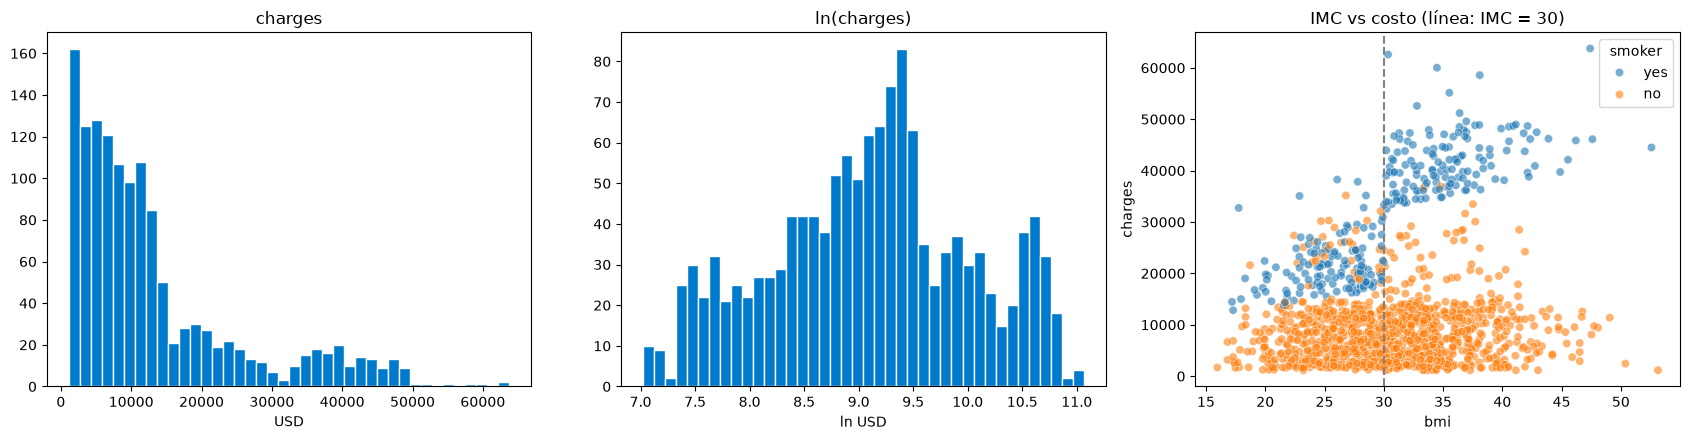

,count,mean,median
smoker,,,
no,1064,"8,434.268","7,345.405"
yes,274,"32,050.232","34,456.348"


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(seguros["charges"], bins=40, color="#007ACC", edgecolor="white")
axes[0].set(title="charges", xlabel="USD")
axes[1].hist(np.log(seguros["charges"]), bins=40, color="#007ACC", edgecolor="white")
axes[1].set(title="ln(charges)", xlabel="ln USD")
sns.scatterplot(data=seguros, x="bmi", y="charges", hue="smoker", alpha=0.6, ax=axes[2])
axes[2].axvline(30, ls="--", c="gray")
axes[2].set_title("IMC vs costo (línea: IMC = 30)")
plt.tight_layout()
plt.show()

seguros.groupby("smoker")["charges"].agg(["count", "mean", "median"])

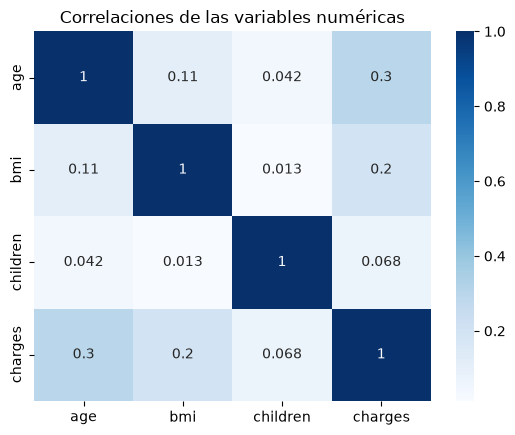

(1070, 8) (268, 8)


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19.000,27.900,0.000,0.000,1.000,0.000,0.000,1.000
1,18.000,33.770,1.000,1.000,0.000,0.000,1.000,0.000
2,28.000,33.000,3.000,1.000,0.000,0.000,1.000,0.000
3,33.000,22.705,0.000,1.000,0.000,1.000,0.000,0.000
4,32.000,28.880,0.000,1.000,0.000,1.000,0.000,0.000


In [6]:
sns.heatmap(seguros[["age", "bmi", "children", "charges"]].corr(), annot=True, cmap="Blues")
plt.title("Correlaciones de las variables numéricas")
plt.show()

seguros_dum = pd.get_dummies(seguros, columns=["sex", "smoker", "region"], drop_first=True, dtype=int)
X_reg = seguros_dum.drop(columns="charges").astype(float)
y_reg = seguros_dum["charges"]
X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=SEED)

print(X_tr_r.shape, X_te_r.shape)
X_reg.head()

**Respuesta.**

- `charges` es fuertemente **asimétrica a la derecha**: la mitad paga menos de ≈ 9 400 USD y una cola larga llega a ≈ 64 000 USD. El RMSE eleva al cuadrado los errores y queda dominado por esa cola; el MAE es más robusto y más fácil de comunicar ("nos equivocamos en promedio X dólares"). En logaritmo la distribución es mucho más simétrica.
- Se ven **tres bandas**: no fumadores (abajo, crecen poco con el IMC), fumadores con IMC < 30 (banda media) y fumadores con IMC ≥ 30 (banda alta, unos 20 000 USD más). El efecto del IMC **depende de si la persona fuma**. Un modelo lineal con `bmi` y `smoker_yes` por separado solo puede sumar efectos constantes, así que no captará ese salto a menos que construyamos una variable para ello (Ejercicio 2).
- Si incluimos las cuatro dicotómicas de región, su suma es siempre 1, exactamente igual a la columna de unos del intercepto: una variable es combinación lineal exacta de otras (**multicolinealidad perfecta**) y $\mathbf{X}^T\mathbf{X}$ no se puede invertir en $\boldsymbol{\beta}^* = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{Y}$. Con `drop_first=True` eliminamos una categoría (`northeast`, `female`, `no`), que queda como **referencia**: cada coeficiente se lee como diferencia frente a ella.

---

<a id="ejercicio-2"></a>
<h2 style="color: #007ACC;">Ejercicio 2. Regresión lineal e interpretación de coeficientes</h2>

**Objetivo:** entrenar el modelo lineal, compararlo contra una referencia sencilla y leer sus coeficientes e inferencia (cuadernos 01 y 02).

1. **Referencia.** Predice para todo el conjunto de prueba la **media de `y_tr_r`** y calcula `metricas_regresion`. Relaciona el resultado con la fórmula del $R^2 = 1 - SS_{res}/SS_{tot}$: ¿qué modelo representa $SS_{tot}$?
2. Entrena `reg_lin = LinearRegression()` con `X_tr_r` **sin escalar** y reporta las métricas en entrenamiento y prueba.
3. Construye una tabla con el coeficiente de cada variable. Como no escalamos, cada $\beta_j$ se lee como "cambio en USD de `charges` cuando $x_j$ aumenta en una unidad, manteniendo lo demás constante". Redacta una frase para `age`, `bmi` y `smoker_yes`.
4. Ajusta el mismo modelo con `statsmodels` (`sm.OLS(y_tr_r, sm.add_constant(X_tr_r)).fit()`, cuaderno 02). ¿Coinciden los coeficientes? ¿Qué variables **no** son significativas al 5 %? Interpreta el intervalo de confianza de `smoker_yes`.
5. Grafica residuales ($y - \hat{y}$) vs. predicciones en prueba, coloreando por `smoker_yes`. Revisa los supuestos de **linealidad** y **homocedasticidad** (cuaderno 01).
6. **Transformaciones de variables.** El cuaderno 01 muestra que un modelo con $x^2$ o $\ln(x)$ sigue siendo lineal en los parámetros. Escribe `agregar_variables(df)` que añada:
   - `age2 = age**2` (término cuadrático),
   - `obeso = 1` si `bmi >= 30`,
   - `fumador_obeso = obeso * smoker_yes` (vale 1 solo para fumadores obesos).

   Reentrena el modelo lineal con estas variables (`reg_lin2`), compara las métricas de prueba y estima de nuevo con `statsmodels`. Interpreta el coeficiente de `fumador_obeso`.

In [7]:
resultados_reg = {}

pred_media = np.full(len(y_te_r), y_tr_r.mean())
resultados_reg["Referencia (media)"] = metricas_regresion(y_te_r, pred_media)

reg_lin = LinearRegression().fit(X_tr_r, y_tr_r)
print("Entrenamiento:", metricas_regresion(y_tr_r, reg_lin.predict(X_tr_r)))
resultados_reg["Lineal"] = metricas_regresion(y_te_r, reg_lin.predict(X_te_r))
pd.DataFrame(resultados_reg).T

Entrenamiento: {'MAE': 4208.234572492225, 'RMSE': 6105.545160099847, 'R2': 0.7417255854683333}


,MAE,RMSE,R2
Referencia (media),"9,593.338","12,465.610",-0.001
Lineal,"4,181.194","5,796.285",0.784


In [8]:
print("Intercepto:", round(reg_lin.intercept_, 1))
pd.Series(reg_lin.coef_, index=X_tr_r.columns, name="USD por unidad").sort_values(key=abs, ascending=False).to_frame()

Intercepto: -11931.2


,USD por unidad
smoker_yes,"23,651.129"
region_southwest,-809.799
region_southeast,-657.864
children,425.279
region_northwest,-370.677
bmi,337.093
age,256.976
sex_male,-18.592


In [9]:
ols = sm.OLS(y_tr_r, sm.add_constant(X_tr_r)).fit()
print(ols.summary().tables[1])

                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.193e+04   1114.505    -10.705      0.000   -1.41e+04   -9744.335
age                256.9757     13.477     19.067      0.000     230.530     283.421
bmi                337.0926     32.471     10.381      0.000     273.378     400.807
children           425.2788    154.655      2.750      0.006     121.814     728.743
sex_male           -18.5917    376.175     -0.049      0.961    -756.722     719.539
smoker_yes        2.365e+04    466.505     50.699      0.000    2.27e+04    2.46e+04
region_northwest  -370.6773    536.873     -0.690      0.490   -1424.130     682.776
region_southeast  -657.8643    539.791     -1.219      0.223   -1717.043     401.314
region_southwest  -809.7994    535.208     -1.513      0.131   -1859.986     240.387


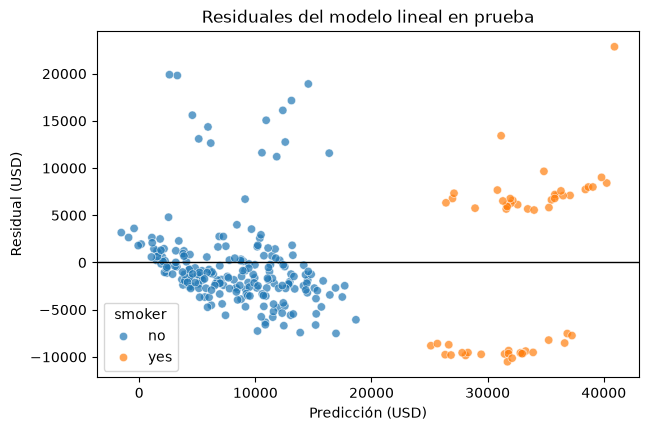

In [10]:
pred_lin = reg_lin.predict(X_te_r)
plt.figure(figsize=(7, 4.5))
sns.scatterplot(x=pred_lin, y=y_te_r - pred_lin, hue=X_te_r["smoker_yes"].map({0: "no", 1: "yes"}), alpha=0.7)
plt.axhline(0, c="k", lw=1)
plt.xlabel("Predicción (USD)")
plt.ylabel("Residual (USD)")
plt.title("Residuales del modelo lineal en prueba")
plt.legend(title="smoker")
plt.show()

In [11]:
def agregar_variables(df):
    df = df.copy()
    df["age2"] = df["age"] ** 2
    df["obeso"] = (df["bmi"] >= 30).astype(float)
    df["fumador_obeso"] = df["obeso"] * df["smoker_yes"]
    return df


X_tr_r2, X_te_r2 = agregar_variables(X_tr_r), agregar_variables(X_te_r)

reg_lin2 = LinearRegression().fit(X_tr_r2, y_tr_r)
resultados_reg["Lineal + transformaciones"] = metricas_regresion(y_te_r, reg_lin2.predict(X_te_r2))
display(pd.DataFrame(resultados_reg).T)

ols2 = sm.OLS(y_tr_r, sm.add_constant(X_tr_r2)).fit()
print(ols2.summary().tables[1])

,MAE,RMSE,R2
Referencia (media),"9,593.338","12,465.610",-0.001
Lineal,"4,181.194","5,796.285",0.784
Lineal + transformaciones,"2,390.440","4,364.346",0.877


                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const              337.0083   1541.353      0.219      0.827   -2687.448    3361.465
age                 -2.2417     67.135     -0.033      0.973    -133.974     129.491
bmi                 97.6856     38.929      2.509      0.012      21.298     174.073
children           611.7378    118.033      5.183      0.000     380.133     843.343
sex_male          -507.6745    274.651     -1.848      0.065   -1046.597      31.248
smoker_yes        1.317e+04    490.607     26.845      0.000    1.22e+04    1.41e+04
region_northwest  -323.7100    391.345     -0.827      0.408   -1091.611     444.191
region_southeast  -710.1477    393.989     -1.802      0.072   -1483.236      62.941
region_southwest -1332.4371    390.708     -3.410      0.001   -2099.087    -565.787
age2                 3.3331      0.838      3.976      0.000     

**Respuesta.**

- La referencia que predice siempre la media tiene $R^2 \approx 0$: $SS_{tot}$ es justamente el error de ese "modelo", así que el $R^2$ mide cuánto mejoramos respecto a predecir la media. El modelo lineal baja el MAE de ≈ 9 600 a ≈ 4 200 USD, con $R^2 \approx 0.78$ en prueba. Entrenamiento y prueba tienen métricas parecidas: no hay sobreentrenamiento; el modelo es demasiado simple (subentrenamiento).
- Lectura de coeficientes (manteniendo lo demás constante): cada **año** de edad suma ≈ 257 USD; cada punto de **IMC** ≈ 337 USD; cada **hijo** ≈ 425 USD, y **fumar** suma ≈ 23 650 USD frente a no fumar. `statsmodels` da exactamente los mismos coeficientes (es el mismo estimador de MCO).
- `sex_male` y las tres regiones **no** son significativas al 5 % (p = 0.96, 0.49, 0.22 y 0.13): sus intervalos de confianza contienen el 0. El intervalo al 95 % de `smoker_yes` es ≈ [22 700, 24 600] USD: estamos muy seguros de que fumar encarece mucho el costo.
- Los residuales **no** son aleatorios: forman bandas y los fumadores tienen residuales grandes y positivos en las predicciones altas. Se violan los supuestos de linealidad y homocedasticidad, y el patrón coincide con las bandas del Ejercicio 1.
- Con `age2`, `obeso` y `fumador_obeso`, el MAE de prueba cae a ≈ 2 390 USD y el $R^2$ sube a ≈ 0.88. El coeficiente de `fumador_obeso` (≈ 20 100 USD, p < 0.001) dice que ser fumador **y** obeso cuesta ≈ 20 000 USD más que la suma de ambos efectos por separado: el salto del IMC aparece casi solo en fumadores. `obeso` por sí solo deja de ser significativo (p ≈ 0.11) y `age` lo absorbe `age2`. Ojo: al reducir el ruido, `region_southwest` pasa a ser significativa (≈ −1 330 USD). La significancia de una variable depende de qué otras variables hay en el modelo.

---

<a id="ejercicio-3"></a>
<h2 style="color: #007ACC;">Ejercicio 3. Regularización: Ridge y Lasso</h2>

**Objetivo:** elegir la fuerza de regularización por validación cruzada y usar Lasso para ver qué variables pesan más (cuadernos 01 y 03).

Trabaja con las variables transformadas (`X_tr_r2`).

1. Define `cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)` (cuaderno 10).
2. Con `GridSearchCV` (`cv=cv_reg`, `scoring="neg_mean_absolute_error"`) busca `alpha` en `np.logspace(-2, 4, 40)` para `make_pipeline(StandardScaler(), Ridge())` y para `make_pipeline(StandardScaler(), Lasso(max_iter=50_000))`. Los parámetros se llaman `ridge__alpha` y `lasso__alpha`.
3. Reporta el mejor `alpha` de cada uno y sus métricas en prueba. Agrégalos a `resultados_reg`.
4. Igual que en el cuaderno 01 (Lasso con `alpha` = 0.1, 1 y 10), estudia el efecto de `alpha`, pero ahora sobre los **coeficientes**: para cada `alpha` en `np.logspace(0, 4, 40)` ajusta el pipeline con Lasso, guarda los coeficientes y grafícalos contra `alpha` (eje x logarítmico).
5. **Preguntas:**
   - ¿Mejoró la regularización el desempeño en prueba? ¿Por qué tiene sentido con ≈ 1 070 filas y 11 variables?
   - ¿Qué variables lleva Lasso a cero primero al aumentar `alpha`? ¿Coincide con los p-valores del Ejercicio 2?
   - ¿Por qué hay que escalar antes de Ridge/Lasso?

In [12]:
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)
alphas = np.logspace(-2, 4, 40)

ridge_reg = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": alphas},
                         cv=cv_reg, scoring="neg_mean_absolute_error").fit(X_tr_r2, y_tr_r)
lasso_reg = GridSearchCV(make_pipeline(StandardScaler(), Lasso(max_iter=50_000)), {"lasso__alpha": alphas},
                         cv=cv_reg, scoring="neg_mean_absolute_error").fit(X_tr_r2, y_tr_r)

for nombre, gs in [("Ridge", ridge_reg), ("Lasso", lasso_reg)]:
    resultados_reg[nombre] = metricas_regresion(y_te_r, gs.predict(X_te_r2))
    print(f"{nombre}: {gs.best_params_}  MAE CV = {-gs.best_score_:,.0f}")

pd.DataFrame(resultados_reg).T

Ridge: {'ridge__alpha': np.float64(0.01)}  MAE CV = 2,496
Lasso: {'lasso__alpha': np.float64(0.01)}  MAE CV = 2,496


,MAE,RMSE,R2
Referencia (media),"9,593.338","12,465.610",-0.001
Lineal,"4,181.194","5,796.285",0.784
Lineal + transformaciones,"2,390.440","4,364.346",0.877
Ridge,"2,390.470","4,364.366",0.877
Lasso,"2,390.457","4,364.360",0.877


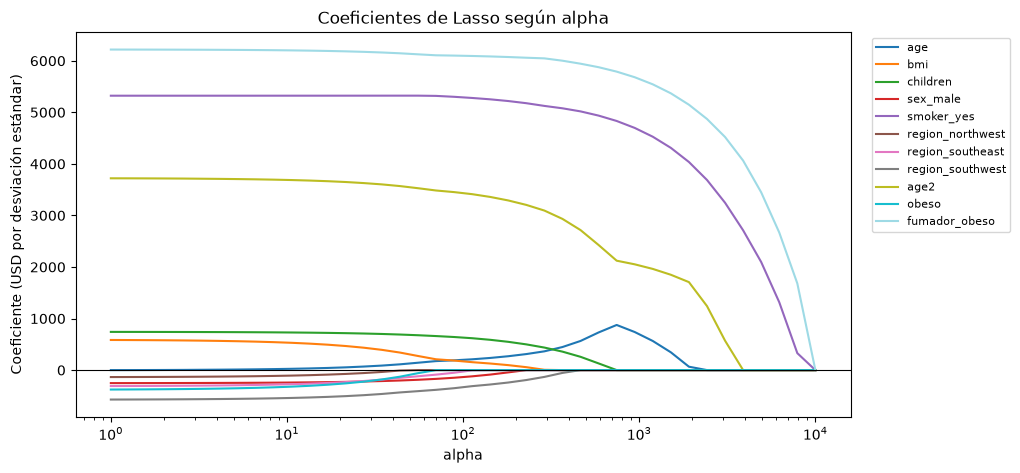

,alpha en que se anula
age,1.000
region_northwest,55.410
obeso,70.170
region_southeast,142.510
sex_male,228.546
bmi,366.524
region_southwest,464.159
children,744.380
age2,"3,888.155"
smoker_yes,"10,000.000"


In [13]:
alphas_path = np.logspace(0, 4, 40)
trayectoria = []
for a in alphas_path:
    pipe = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=50_000)).fit(X_tr_r2, y_tr_r)
    trayectoria.append(pipe[-1].coef_)
trayectoria = pd.DataFrame(trayectoria, index=alphas_path, columns=X_tr_r2.columns)

ax = trayectoria.plot(logx=True, figsize=(10, 5), cmap="tab20")
ax.axhline(0, c="k", lw=0.8)
ax.set(xlabel="alpha", ylabel="Coeficiente (USD por desviación estándar)", title="Coeficientes de Lasso según alpha")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.show()

# Primer alpha en el que cada coeficiente queda en cero
en_cero = trayectoria.abs() < 1e-6
en_cero.idxmax().where(en_cero.any()).sort_values().to_frame("alpha en que se anula")

**Respuesta.**

- Ridge y Lasso quedan **empatados** con la regresión lineal transformada (MAE ≈ 2 390 USD en los tres) y el mejor `alpha` es el **extremo inferior** de la grilla (0.01): la validación cruzada nos dice que *no regularicemos*. Con ≈ 1 070 observaciones y 11 variables el modelo no sobreentrena, así que no hay nada que la regularización pueda corregir. Ayuda cuando hay muchas variables, pocas filas o mucha multicolinealidad (como en el ejemplo polinómico de grado 10 del cuaderno 01).
- Al aumentar `alpha`, Lasso anula primero `age` (redundante con `age2`), `region_northwest`, `obeso`, `region_southeast` y `sex_male`; después `bmi`, `region_southwest` y `children`. Las últimas en sobrevivir son `age2`, `smoker_yes` y `fumador_obeso`. En general coincide con los p-valores: lo no significativo sale primero. La excepción es `age`, que sale por **multicolinealidad** con `age2` y no por falta de efecto: Lasso se queda con una de dos variables casi equivalentes.
- La penalización $\alpha\sum|\beta_j|$ (o $\alpha\sum\beta_j^2$) depende de la escala: una variable medida en unidades pequeñas necesita un coeficiente grande y sería penalizada injustamente. Escalar pone a todas las variables en igualdad de condiciones.

---

<a id="ejercicio-4"></a>
<h2 style="color: #007ACC;">Ejercicio 4. KNN, SVR y árbol de regresión</h2>

**Objetivo:** ajustar modelos no lineales con búsqueda de hiperparámetros y compararlos con los lineales (cuadernos 06, 07, 08 y 10).

Usa las **variables originales** (`X_tr_r`, sin las transformaciones del Ejercicio 2) para ver si estos modelos descubren la estructura por sí solos.
Usa `GridSearchCV` con `cv=cv_reg` y `scoring="neg_mean_absolute_error"` en todos los casos.

1. **KNN:** `make_pipeline(StandardScaler(), KNeighborsRegressor())` con `n_neighbors` en `range(1, 41, 2)` y `metric` en `["euclidean", "manhattan"]`.
2. **SVR:** `make_pipeline(StandardScaler(), SVR())`. Recuerda (cuaderno 06) que $\epsilon$ es el ancho del "tubo" alrededor de la predicción y se mide **en las unidades de $y$** (aquí, dólares). Busca en una lista de dos grillas:
   - kernel `linear` con `C` en `[100, 1_000, 10_000]` y `epsilon` en `[100, 1_000]`;
   - kernel `rbf` con `C` en `[1_000, 10_000, 100_000]`, `gamma` en `["scale", 0.1, 1]` y `epsilon` en `[100, 1_000]`.
3. **Árbol:** `DecisionTreeRegressor(random_state=SEED)` con `max_depth` en `[2, 3, 4, 5, 6, 8, 10, None]` y `min_samples_leaf` en `[1, 5, 10, 20, 40]`. ¿Hace falta escalar para un árbol? (Revisa las ventajas del árbol en el cuaderno 08).
4. Para cada modelo reporta los mejores hiperparámetros, el MAE de entrenamiento y las métricas de prueba. Completa `resultados_reg` y grafica el MAE de prueba de todos los modelos en un gráfico de barras.
5. **Preguntas:**
   - ¿Qué modelo gana? ¿Por qué el árbol, sin la variable `fumador_obeso`, se acerca al modelo lineal que sí la tiene?
   - Ajusta aparte un árbol **sin límite de profundidad** y compara su MAE de entrenamiento y de prueba. Relaciónalo con el **sobreentrenamiento** (cuaderno 00).
   - ¿Qué ocurre con KNN cuando $k=1$? ¿Y cuando $k$ es muy grande?

In [14]:
knn_reg = GridSearchCV(
    make_pipeline(StandardScaler(), KNeighborsRegressor()),
    {"kneighborsregressor__n_neighbors": range(1, 41, 2),
     "kneighborsregressor__metric": ["euclidean", "manhattan"]},
    cv=cv_reg, scoring="neg_mean_absolute_error",
).fit(X_tr_r, y_tr_r)

svr_reg = GridSearchCV(
    make_pipeline(StandardScaler(), SVR()),
    [
        {"svr__kernel": ["linear"], "svr__C": [100, 1_000, 10_000], "svr__epsilon": [100, 1_000]},
        {"svr__kernel": ["rbf"], "svr__C": [1_000, 10_000, 100_000], "svr__gamma": ["scale", 0.1, 1],
         "svr__epsilon": [100, 1_000]},
    ],
    cv=cv_reg, scoring="neg_mean_absolute_error",
).fit(X_tr_r, y_tr_r)

arbol_reg = GridSearchCV(
    DecisionTreeRegressor(random_state=SEED),
    {"max_depth": [2, 3, 4, 5, 6, 8, 10, None], "min_samples_leaf": [1, 5, 10, 20, 40]},
    cv=cv_reg, scoring="neg_mean_absolute_error",
).fit(X_tr_r, y_tr_r)

for nombre, gs in [("KNN", knn_reg), ("SVR", svr_reg), ("Árbol", arbol_reg)]:
    mae_tr = mean_absolute_error(y_tr_r, gs.predict(X_tr_r))
    resultados_reg[nombre] = metricas_regresion(y_te_r, gs.predict(X_te_r))
    print(f"{nombre:6s} MAE entrenamiento = {mae_tr:8,.0f} | {gs.best_params_}")

tabla_reg = pd.DataFrame(resultados_reg).T.sort_values("MAE")
tabla_reg

KNN    MAE entrenamiento =    2,209 | {'kneighborsregressor__metric': 'manhattan', 'kneighborsregressor__n_neighbors': 3}
SVR    MAE entrenamiento =    1,847 | {'svr__C': 10000, 'svr__epsilon': 100, 'svr__gamma': 0.1, 'svr__kernel': 'rbf'}
Árbol  MAE entrenamiento =    2,364 | {'max_depth': 5, 'min_samples_leaf': 5}


,MAE,RMSE,R2
SVR,"1,846.547","4,737.592",0.855
Lineal + transformaciones,"2,390.440","4,364.346",0.877
Lasso,"2,390.457","4,364.360",0.877
Ridge,"2,390.470","4,364.366",0.877
Árbol,"2,666.824","4,509.200",0.869
KNN,"3,405.163","5,609.183",0.797
Lineal,"4,181.194","5,796.285",0.784
Referencia (media),"9,593.338","12,465.610",-0.001


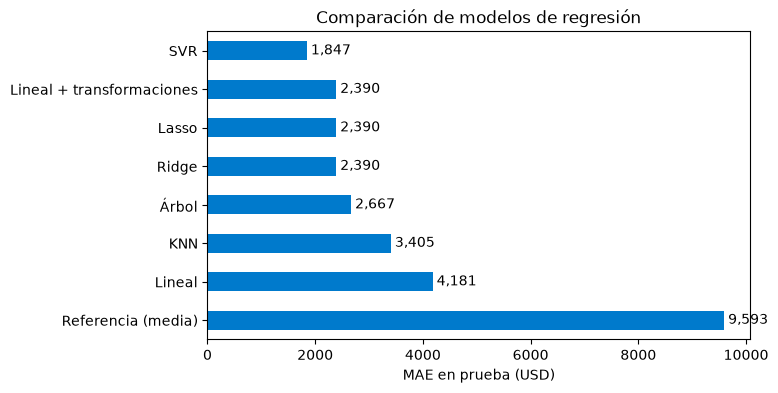

Árbol sin límite -> MAE entrenamiento: 30 | MAE prueba: 3384 | profundidad: 21 | hojas: 1068


In [15]:
ax = tabla_reg["MAE"].plot.barh(figsize=(7, 4), color="#007ACC")
ax.invert_yaxis()
ax.set(xlabel="MAE en prueba (USD)", title="Comparación de modelos de regresión")
for i, v in enumerate(tabla_reg["MAE"]):
    ax.text(v, i, f" {v:,.0f}", va="center")
plt.show()

arbol_libre = DecisionTreeRegressor(random_state=SEED).fit(X_tr_r, y_tr_r)
print("Árbol sin límite -> MAE entrenamiento:", round(mean_absolute_error(y_tr_r, arbol_libre.predict(X_tr_r))),
      "| MAE prueba:", round(mean_absolute_error(y_te_r, arbol_libre.predict(X_te_r))),
      "| profundidad:", arbol_libre.get_depth(), "| hojas:", arbol_libre.get_n_leaves())

**Respuesta.**

- El **SVR** (kernel RBF, `C=10 000`, `gamma=0.1`, `epsilon=100`) gana en MAE (≈ 1 850 USD). El modelo lineal con transformaciones tiene el mejor RMSE y $R^2$ (0.877), y el **árbol** (profundidad 5, hojas de ≥ 5 observaciones) queda cerca (MAE ≈ 2 670, $R^2$ ≈ 0.87). **KNN** mejora sobre la regresión lineal simple (MAE ≈ 3 400) pero queda atrás: con `k=3` sus predicciones son ruidosas, y en la distancia la variable `smoker_yes` pesa lo mismo que cualquier otra variable escalada.
- El árbol encuentra la estructura solo porque **divide el espacio de forma jerárquica** (cuaderno 08): primero por `smoker_yes`, luego, dentro de los fumadores, por `bmi ≈ 30`, y después por `age`. Esas reglas anidadas reproducen lo que en el modelo lineal tuvimos que construir a mano con `fumador_obeso`.
- El árbol sin límite llega a profundidad 21 con 1 068 hojas para 1 070 filas: MAE de entrenamiento ≈ 30 USD contra ≈ 3 380 en prueba, peor que el árbol con límites (≈ 2 670). Es **sobreentrenamiento**: memoriza el ruido de entrenamiento y no generaliza.
- Con `k=1` KNN copia el valor del vecino más cercano: error de entrenamiento casi nulo y predicciones ruidosas (sobreentrenamiento). Con `k` muy grande cada predicción se acerca a la media global (subentrenamiento). El óptimo por validación cruzada está en medio.

---

<a id="ejercicio-5"></a>
<h2 style="color: #007ACC;">Ejercicio 5. Interpretación de modelos de regresión</h2>

**Objetivo:** explicar *qué* aprendió cada modelo y verificar si cuentan la misma historia.

1. **Reglas del árbol.** Ajusta un `DecisionTreeRegressor(max_depth=3)` (para que sea legible) y dibújalo con `plot_tree` (cuaderno 08). Traduce las tres hojas con mayor costo predicho a reglas en español ("si fuma y ...").
2. **¿Qué variables importan?** Reúne la evidencia que ya tienes:
   - signo, magnitud y p-valor de los coeficientes del modelo lineal (Ejercicio 2);
   - el orden en que Lasso anula los coeficientes (Ejercicio 3);
   - las variables que usa el árbol en sus primeras divisiones.

   ¿Coinciden?
3. **Curvas "qué pasaría si".** Como en los cuadernos 07 y 08 (donde graficamos la predicción sobre una grilla de valores de $x$), construye una grilla de IMC entre 18 y 50 para una persona de 45 años, hombre, 2 hijos, región `southeast`. Grafica la predicción de cada modelo (lineal, lineal con transformaciones, KNN, SVR y árbol) en función del IMC, con una curva para **fumador** y otra para **no fumador**.
   - Pista: escribe una función `crear_personas(...)` que arme el DataFrame con las mismas columnas de `X_reg`.
4. Para la misma persona con IMC 33, construye una tabla con la predicción de cada modelo si fuma y si no fuma, y la diferencia. ¿Cuánto "cuesta" fumar según cada modelo? ¿Por qué el modelo lineal sin transformaciones da una cifra distinta a los demás?

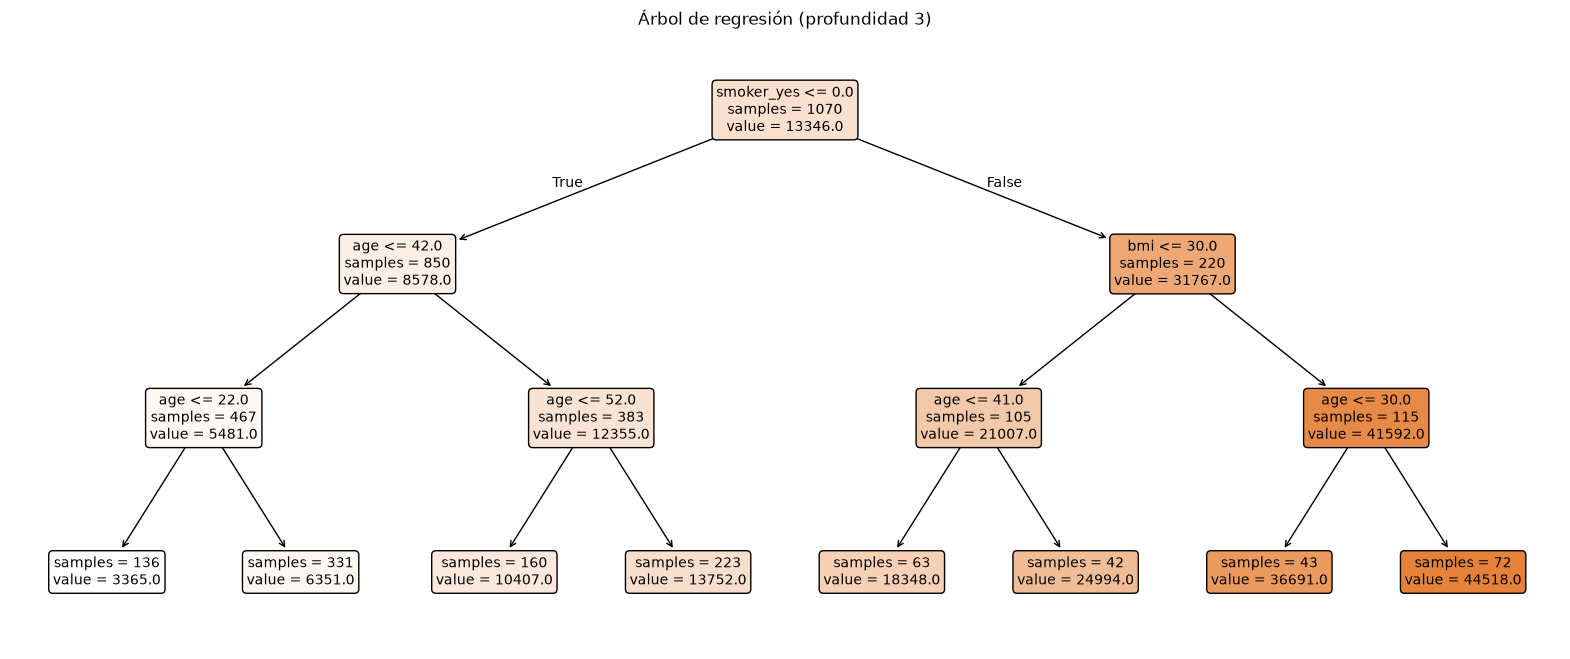

In [16]:
arbol_3 = DecisionTreeRegressor(max_depth=3, random_state=SEED).fit(X_tr_r, y_tr_r)
plt.figure(figsize=(20, 8))
plot_tree(arbol_3, feature_names=list(X_tr_r.columns), filled=True, rounded=True, impurity=False, precision=0, fontsize=10)
plt.title("Árbol de regresión (profundidad 3)")
plt.show()

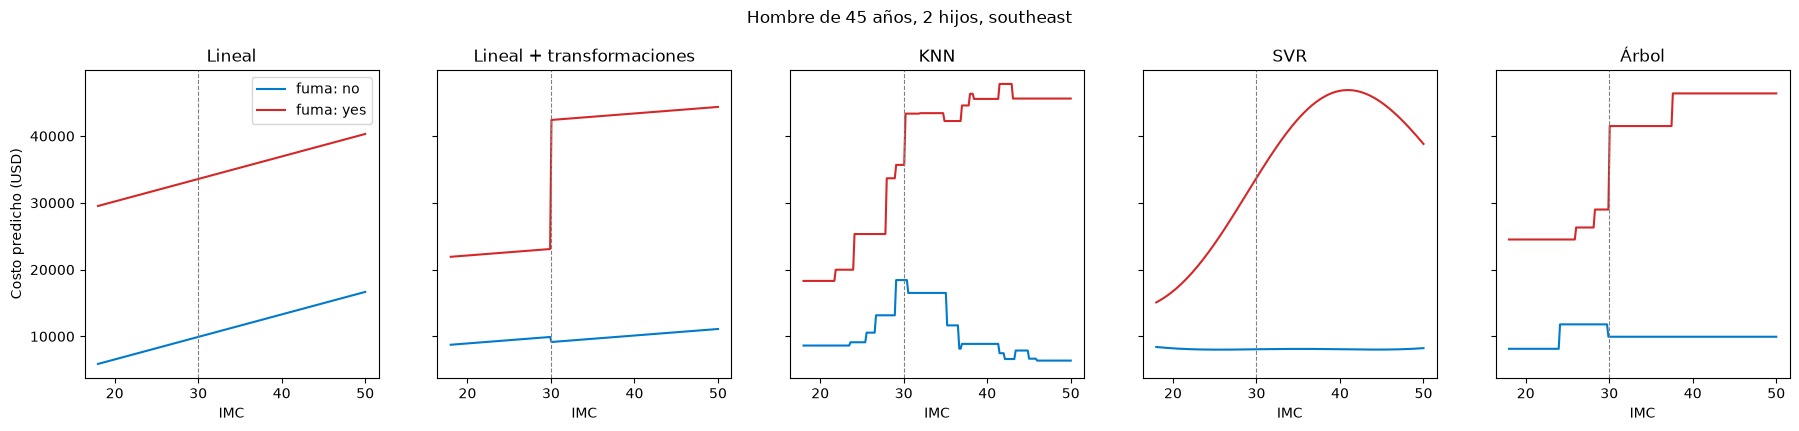

In [17]:
def crear_personas(age, bmi, children, sex, smoker, region):
    """Arma filas con las mismas columnas dicotómicas de X_reg. `bmi` puede ser un arreglo."""
    bmi = np.atleast_1d(bmi)
    df = pd.DataFrame({"age": age, "bmi": bmi, "children": children})
    df["sex_male"] = float(sex == "male")
    df["smoker_yes"] = float(smoker == "yes")
    for r in ["northwest", "southeast", "southwest"]:
        df[f"region_{r}"] = float(region == r)
    return df[X_reg.columns]


modelos_reg = {
    "Lineal": (reg_lin, False),
    "Lineal + transformaciones": (reg_lin2, True),
    "KNN": (knn_reg, False),
    "SVR": (svr_reg, False),
    "Árbol": (arbol_reg, False),
}

grilla_imc = np.linspace(18, 50, 200)
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=True)
for ax, (nombre, (modelo, transformar)) in zip(axes, modelos_reg.items()):
    for fuma, color in [("no", "#007ACC"), ("yes", "#d62728")]:
        X_p = crear_personas(45, grilla_imc, 2, "male", fuma, "southeast")
        X_p = agregar_variables(X_p) if transformar else X_p
        ax.plot(grilla_imc, modelo.predict(X_p), color=color, label=f"fuma: {fuma}")
    ax.axvline(30, ls="--", c="gray", lw=0.8)
    ax.set(title=nombre, xlabel="IMC")
axes[0].set_ylabel("Costo predicho (USD)")
axes[0].legend()
plt.suptitle("Hombre de 45 años, 2 hijos, southeast", y=1.03)
plt.show()

In [18]:
que_pasaria = {}
for nombre, (modelo, transformar) in modelos_reg.items():
    fila = {}
    for fuma in ["no", "yes"]:
        X_p = crear_personas(45, 33, 2, "male", fuma, "southeast")
        X_p = agregar_variables(X_p) if transformar else X_p
        fila["Fuma" if fuma == "yes" else "No fuma"] = modelo.predict(X_p)[0]
    que_pasaria[nombre] = fila

que_pasaria = pd.DataFrame(que_pasaria).T
que_pasaria["Costo de fumar"] = que_pasaria["Fuma"] - que_pasaria["No fuma"]
que_pasaria

,No fuma,Fuma,Costo de fumar
Lineal,"10,930.844","34,581.972","23,651.129"
Lineal + transformaciones,"9,447.558","42,699.719","33,252.161"
KNN,"16,509.831","43,428.585","26,918.754"
SVR,"8,115.167","39,426.317","31,311.150"
Árbol,"9,947.545","41,496.573","31,549.028"


**Respuesta.**

- **Reglas del árbol** (profundidad 3): la primera división es `smoker_yes`; en fumadores la segunda es `bmi ≤ 30` y luego la edad. Las hojas más caras son: *fumador, IMC > 30 y más de 30 años* (≈ 44 500 USD); *fumador, IMC > 30 y hasta 30 años* (≈ 36 700 USD); *fumador con IMC ≤ 30 y más de 41 años* (≈ 25 000 USD). Los no fumadores se separan solo por edad, entre ≈ 3 400 USD (≤ 22 años) y ≈ 13 750 USD (> 52 años).
- **Las tres fuentes coinciden:** fumar (junto con su efecto conjunto con la obesidad), la edad y el IMC son lo que importa. Son los coeficientes más significativos, los últimos que Lasso anula y las únicas variables que usa el árbol en sus tres primeros niveles. Sexo y región no aparecen en el árbol, Lasso las elimina pronto y en su mayoría no son significativas.
- **Curvas "qué pasaría si":**
  - el lineal simple da dos **rectas paralelas**: fumar suma siempre lo mismo, sin importar el IMC;
  - el lineal transformado tiene un **salto en IMC = 30 solo para fumadores**, porque así lo construimos;
  - el árbol muestra el mismo salto, pero **en escalones**, y lo aprendió solo;
  - el SVR lo dibuja como una curva suave en forma de S, aunque **baja después de IMC ≈ 40** porque hay pocos datos con IMC tan alto y el kernel RBF "regresa" hacia valores típicos (no se debe extrapolar donde no hay datos);
  - KNN es irregular, incluso para no fumadores, porque con `k=3` cada predicción depende de muy pocas personas.
- **Costo de fumar** para esta persona (IMC 33): ≈ 31 300 USD (SVR), ≈ 31 500 (árbol), ≈ 33 300 (lineal transformado) y ≈ 26 900 (KNN). El lineal sin transformaciones da ≈ 23 650 USD, el *promedio* del efecto de fumar para cualquier IMC: **subestima** el costo en obesos y lo **sobreestima** en personas con IMC normal.

---

<h1 style="color: #FECB05;">Parte II — Clasificación: diabetes en mujeres pima</h1>

El *National Institute of Diabetes and Digestive and Kidney Diseases* siguió a mujeres de la comunidad pima (Arizona) de 21 años o más.
Queremos predecir si una paciente **desarrollará diabetes en los próximos 5 años** para priorizar un programa de prevención.

| Variable | Descripción |
|---|---|
| `embarazos` | Número de embarazos |
| `glucosa` | Glucosa plasmática a las 2 h en prueba oral de tolerancia (mg/dL) |
| `presion` | Presión diastólica (mm Hg) |
| `pliegue` | Pliegue cutáneo del tríceps (mm) |
| `insulina` | Insulina sérica a las 2 h (μU/mL) |
| `imc` | Índice de masa corporal |
| `pedigri` | Función de pedigrí de diabetes (antecedentes familiares) |
| `edad` | Años |
| `diabetes` | **Objetivo**: 1 = desarrolló diabetes |

El archivo **no trae encabezado**; usa la lista `cols_pima` de abajo.

In [19]:
cols_pima = ["embarazos", "glucosa", "presion", "pliegue", "insulina", "imc", "pedigri", "edad", "diabetes"]

---

<a id="ejercicio-6"></a>
<h2 style="color: #007ACC;">Ejercicio 6. Exploración y limpieza</h2>

**Objetivo:** detectar problemas de calidad que no se ven con `isna()` y preparar una partición estratificada.

1. Carga `URL_PIMA` con `header=None, names=cols_pima` en `pima`. Verifica `isna().sum()`.
2. Cuenta cuántos **ceros** hay en cada variable. ¿Cuáles de esos ceros son **fisiológicamente imposibles**? (Nadie vivo tiene glucosa, presión o IMC igual a 0).
3. Limpieza:
   - elimina las columnas `insulina` y `pliegue` (demasiados ceros imposibles para usarlas);
   - elimina las filas con cero en `glucosa`, `presion` o `imc`. ¿Cuántas filas quedan?
4. Muestra la proporción de cada clase, los boxplots de cada variable por clase y el mapa de calor de correlaciones.
5. Separa `X_clf` y `y_clf` y haz una partición 75/25 **estratificada** (`stratify=y_clf`, cuaderno 10) con `random_state=SEED`: `X_tr_c, X_te_c, y_tr_c, y_te_c`.
6. **Referencia.** ¿Qué exactitud y qué sensibilidad tendría en prueba un "modelo" que siempre responde 0 (no diabetes)? Calcúlalo con `metricas_clasificacion`.
7. **Preguntas:**
   - ¿Qué pasaría si dejáramos los ceros de `insulina` como valores reales en un modelo lineal o en KNN?
   - ¿Por qué estratificar? ¿Por qué la exactitud de la referencia es engañosa aquí?

In [20]:
pima = pd.read_csv(URL_PIMA, header=None, names=cols_pima)
print("Dimensiones:", pima.shape)
print("Faltantes explícitos:", pima.isna().sum().sum())
(pima.drop(columns="diabetes") == 0).sum().rename("ceros").to_frame().T

Dimensiones: (768, 9)
Faltantes explícitos: 0


,embarazos,glucosa,presion,pliegue,insulina,imc,pedigri,edad
ceros,111,5,35,227,374,11,0,0


In [21]:
pima_limpio = pima.drop(columns=["insulina", "pliegue"])
pima_limpio = pima_limpio[(pima_limpio[["glucosa", "presion", "imc"]] != 0).all(axis=1)]
print("Filas antes:", len(pima), "| filas después:", len(pima_limpio))
print("Proporción de clases:")
pima_limpio["diabetes"].value_counts(normalize=True)

Filas antes: 768 | filas después: 724
Proporción de clases:


diabetes
0   0.656
1   0.344
Name: proportion, dtype: float64

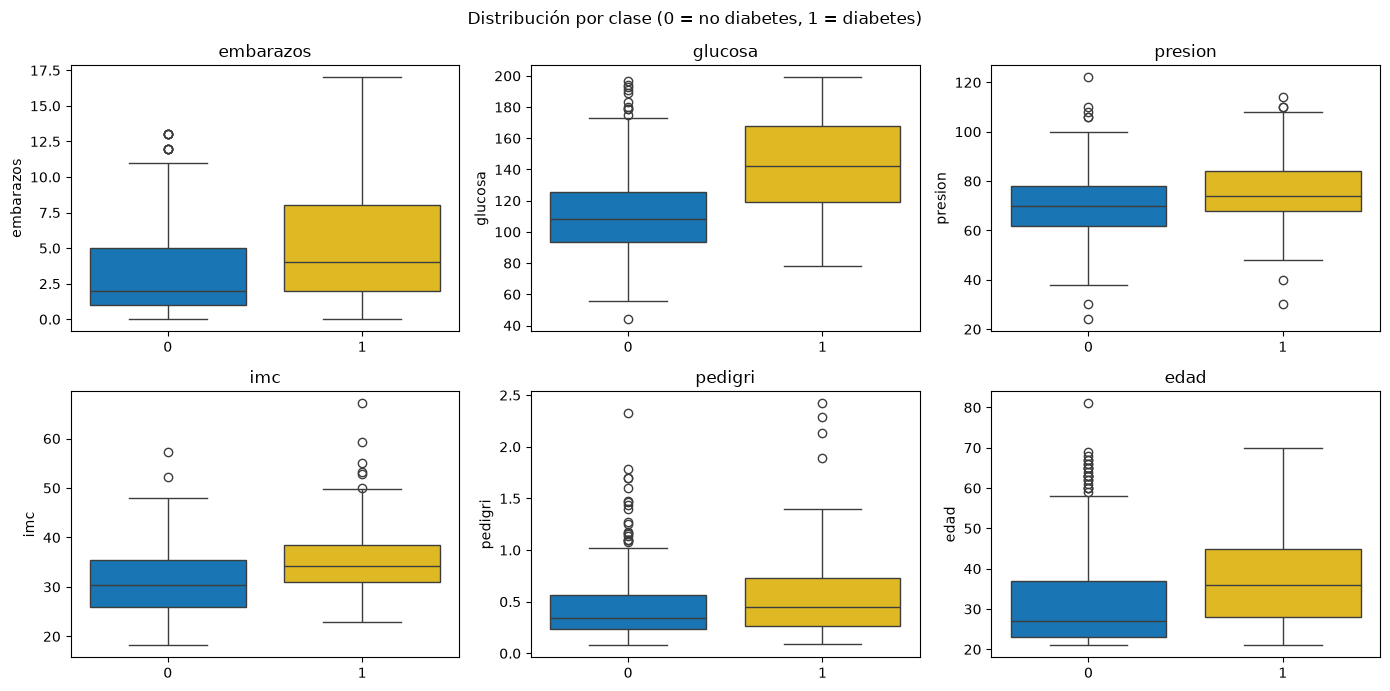

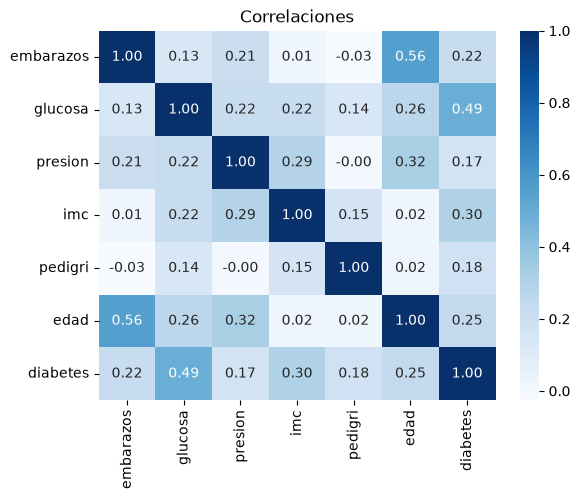

In [22]:
variables = [c for c in pima_limpio.columns if c != "diabetes"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), variables):
    sns.boxplot(data=pima_limpio, x="diabetes", y=col, ax=ax, hue="diabetes", palette=["#007ACC", "#FECB05"], legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Distribución por clase (0 = no diabetes, 1 = diabetes)")
plt.tight_layout()
plt.show()

sns.heatmap(pima_limpio.corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlaciones")
plt.show()

In [23]:
X_clf = pima_limpio.drop(columns="diabetes")
y_clf = pima_limpio["diabetes"]
X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(
    X_clf, y_clf, test_size=0.25, stratify=y_clf, random_state=SEED
)
print("Proporción de positivos entrenamiento/prueba:", round(y_tr_c.mean(), 3), round(y_te_c.mean(), 3))

resultados_clf = {}
resultados_clf["Referencia (siempre 0)"] = metricas_clasificacion(y_te_c, np.zeros(len(y_te_c), dtype=int))
pd.DataFrame(resultados_clf).T

Proporción de positivos entrenamiento/prueba: 0.344 0.343


,exactitud,precision,sensibilidad,f1
Referencia (siempre 0),0.657,0.000,0.000,0.000


**Respuesta.**

- Hay ceros imposibles en `glucosa` (5), `presion` (35), `pliegue` (227), `insulina` (374, casi la mitad) e `imc` (11). `embarazos = 0` sí es un valor válido. Tras eliminar `insulina` y `pliegue` y las filas con ceros en las otras tres, quedan **724 de 768** pacientes.
- Si dejáramos los ceros de `insulina` como valores reales, el modelo los trataría como mediciones extremas. En un modelo lineal distorsionarían la pendiente; en KNN crearían distancias artificiales (dos pacientes "parecidas" solo porque a ambas les faltó el examen).
- Solo ≈ 34 % de las pacientes son positivas. Estratificar (cuaderno 10) asegura que entrenamiento y prueba conserven esa proporción (0.344 y 0.343). Sin estratificar, con 181 casos de prueba, las métricas podrían cambiar bastante por azar.
- Responder siempre "no diabetes" logra **≈ 66 % de exactitud** con **sensibilidad 0**: no detecta a ninguna paciente. Por eso en este problema reportamos precisión, sensibilidad y F1, no solo la exactitud.

---

<a id="ejercicio-7"></a>
<h2 style="color: #007ACC;">Ejercicio 7. Regresión logística y matriz de confusión</h2>

**Objetivo:** entrenar el clasificador lineal de referencia, evaluarlo con las métricas de la matriz de confusión e interpretar sus coeficientes (cuadernos 04 y 05).

1. Entrena `logit = make_pipeline(StandardScaler(), LogisticRegression())`.
2. En prueba: dibuja la matriz de confusión (`ConfusionMatrixDisplay`), imprime `classification_report` y agrega `metricas_clasificacion` a `resultados_clf`.
3. A partir de la matriz (`confusion_matrix`), identifica VP, FP, VN y FN (cuaderno 05) y calcula **a mano** la exactitud, la precisión, la sensibilidad y la F1. Verifica que coincidan con sklearn (es la tarea que quedó propuesta en el cuaderno 04).
4. **Coeficientes.** El modelo calcula $\hat{p} = \sigma(\mathbf{x}^T\boldsymbol{\beta})$. Como las variables están estandarizadas, cada $\beta_j$ indica cuánto cambia $\mathbf{x}^T\boldsymbol{\beta}$ cuando la variable aumenta **una desviación estándar**. Grafica los coeficientes ordenados.
   - ¿Qué signo tienen? Un $\beta_j > 0$, ¿aumenta o disminuye $\hat{p}$?
   - ¿Por qué podemos comparar sus magnitudes entre variables solo porque escalamos?
5. **Pregunta:** en este contexto, ¿qué error de la matriz de confusión es más grave: el falso positivo o el falso negativo? ¿Qué métrica priorizarías?

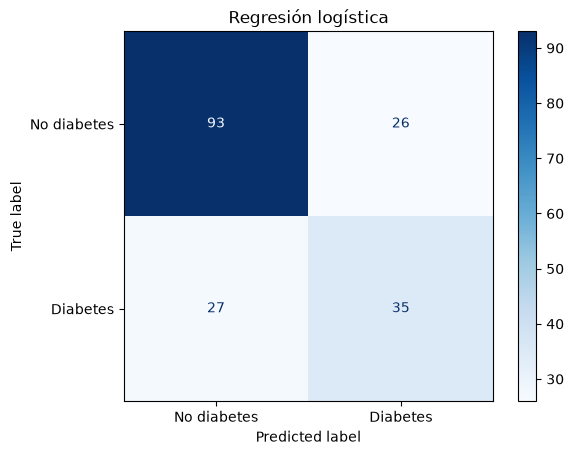

              precision    recall  f1-score   support

 No diabetes       0.78      0.78      0.78       119
    Diabetes       0.57      0.56      0.57        62

    accuracy                           0.71       181
   macro avg       0.67      0.67      0.67       181
weighted avg       0.71      0.71      0.71       181



In [24]:
logit = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_tr_c, y_tr_c)
pred_logit = logit.predict(X_te_c)
resultados_clf["Logística"] = metricas_clasificacion(y_te_c, pred_logit)

ConfusionMatrixDisplay.from_predictions(y_te_c, pred_logit, display_labels=["No diabetes", "Diabetes"], cmap="Blues")
plt.title("Regresión logística")
plt.show()
print(classification_report(y_te_c, pred_logit, target_names=["No diabetes", "Diabetes"]))

In [25]:
vn, fp, fn, vp = confusion_matrix(y_te_c, pred_logit).ravel()
precision = vp / (vp + fp)
sensibilidad = vp / (vp + fn)
print(f"VP={vp} FP={fp} FN={fn} VN={vn}")
print(f"Exactitud    = (VP+VN)/total     = {(vp + vn) / (vp + vn + fp + fn):.3f}")
print(f"Precisión    = VP/(VP+FP)        = {precision:.3f}")
print(f"Sensibilidad = VP/(VP+FN)        = {sensibilidad:.3f}")
print(f"F1           = 2VP/(2VP+FP+FN)   = {2 * vp / (2 * vp + fp + fn):.3f}")
pd.Series(resultados_clf["Logística"]).to_frame("sklearn").T

VP=35 FP=26 FN=27 VN=93
Exactitud    = (VP+VN)/total     = 0.707
Precisión    = VP/(VP+FP)        = 0.574
Sensibilidad = VP/(VP+FN)        = 0.565
F1           = 2VP/(2VP+FP+FN)   = 0.569


,exactitud,precision,sensibilidad,f1
sklearn,0.707,0.574,0.565,0.569


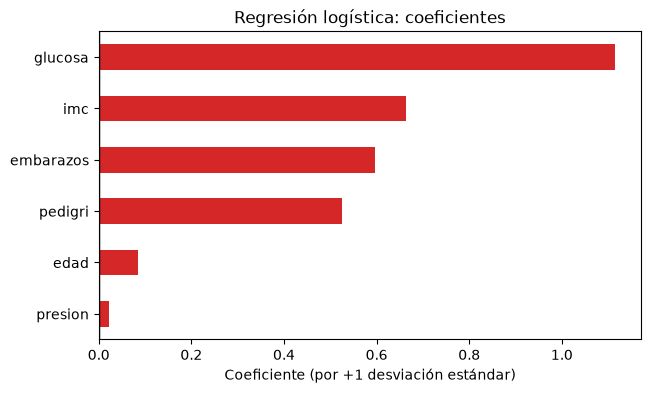

Intercepto: -0.917


,beta
glucosa,1.116
imc,0.664
embarazos,0.597
pedigri,0.525
edad,0.084
presion,0.022


In [26]:
beta = pd.Series(logit[-1].coef_[0], index=X_clf.columns).sort_values()
ax = beta.plot.barh(figsize=(7, 4), color=np.where(beta > 0, "#d62728", "#007ACC"))
ax.axvline(0, c="k", lw=1)
ax.set(xlabel="Coeficiente (por +1 desviación estándar)", title="Regresión logística: coeficientes")
plt.show()
print("Intercepto:", round(logit[-1].intercept_[0], 3))
beta.sort_values(ascending=False).to_frame("beta")

**Respuesta.**

- En prueba la logística logra exactitud ≈ 0.71, precisión ≈ 0.57, sensibilidad ≈ 0.56 y F1 ≈ 0.57 (VP = 35, FP = 26, FN = 27, VN = 93). Los cálculos a mano coinciden con sklearn. Detecta solo **35 de 62** pacientes que desarrollarán diabetes.
- Todos los coeficientes son **positivos**: aumentar cualquiera de las variables aumenta $\mathbf{x}^T\boldsymbol{\beta}$ y, como $\sigma$ es creciente, aumenta $\hat{p}$. El orden es `glucosa` (1.12) ≫ `imc` (0.66) ≈ `embarazos` (0.60) ≈ `pedigri` (0.53) ≫ `edad` (0.08) ≈ `presion` (0.02). Sumar una desviación estándar de glucosa (≈ 30 mg/dL) mueve $\mathbf{x}^T\boldsymbol{\beta}$ casi el doble que una desviación de IMC.
- Solo podemos comparar magnitudes porque estandarizamos: sin escalar, el coeficiente de `pedigri` (rango 0–2.4) sería mucho mayor que el de `glucosa` (rango 44–199) aunque su efecto real fuera menor. El coeficiente depende de las unidades de la variable.
- El error grave es el **falso negativo**: una paciente en riesgo que no entra al programa de prevención. Un falso positivo cuesta una consulta o un examen adicional. Por eso conviene priorizar la **sensibilidad** (o al menos la F1), no la exactitud. Esto motiva el Ejercicio 8.

---

<a id="ejercicio-8"></a>
<h2 style="color: #007ACC;">Ejercicio 8. El umbral de decisión</h2>

**Objetivo:** entender que la regresión logística produce una probabilidad $\hat{p}$ y que la clase se decide con un umbral.

En el cuaderno 04 definimos $\hat{y} = 1$ si $\hat{p} \geq 0.5$. Ese 0.5 es una **decisión**, no algo que el modelo aprenda. Veamos qué pasa si lo movemos.

1. Con `logit.predict_proba(X)[:, 1]` se obtiene $\hat{p}$ para cada paciente. Comprueba que `(p_hat >= 0.5)` reproduce exactamente `logit.predict(X_te_c)`.
2. **Elegir el umbral sin mirar la prueba.** Usa el mismo esquema de K-Folds del cuaderno 10 (`KFold(n_splits=5, shuffle=True, random_state=SEED)` y un ciclo `for` sobre `kf.split(X_tr_c)`): en cada partición entrena la logística con $K-1$ subconjuntos y calcula $\hat{p}$ del subconjunto que quedó por fuera. Al final tendrás un $\hat{p}$ "fuera de muestra" para cada paciente de entrenamiento.
3. Para umbrales en `np.arange(0.05, 0.96, 0.05)` calcula la precisión, la sensibilidad y la F1 con esas probabilidades y grafícalas contra el umbral.
4. Elige el umbral **más alto** que garantice una sensibilidad ≥ 0.80.
5. Aplica los umbrales 0.5 y el elegido **una sola vez** al conjunto de prueba y compara matrices de confusión y métricas.
6. **Preguntas:**
   - ¿Por qué no elegir el umbral directamente con el conjunto de prueba?
   - ¿Qué umbral recomendarías para un programa de tamizaje barato? ¿Y para decidir un tratamiento costoso con efectos adversos?

¿(p_hat >= 0.5) coincide con predict? True


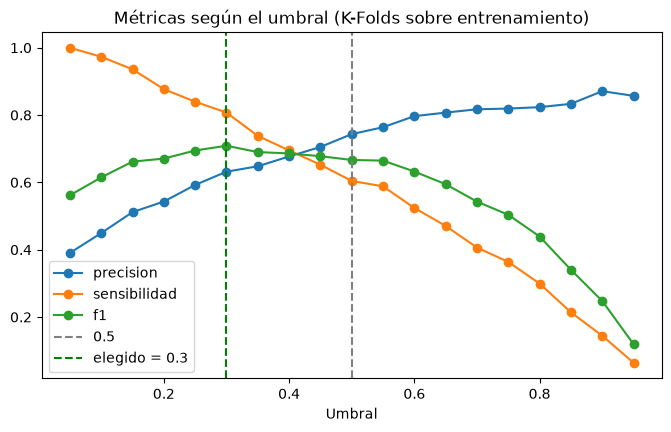

Umbral elegido: 0.3


In [27]:
p_hat_te = logit.predict_proba(X_te_c)[:, 1]
print("¿(p_hat >= 0.5) coincide con predict?", np.array_equal((p_hat_te >= 0.5).astype(int), pred_logit))

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
p_hat_oof = np.zeros(len(X_tr_c))
for train_ix, val_ix in kf.split(X_tr_c):
    modelo = make_pipeline(StandardScaler(), LogisticRegression())
    modelo.fit(X_tr_c.iloc[train_ix], y_tr_c.iloc[train_ix])
    p_hat_oof[val_ix] = modelo.predict_proba(X_tr_c.iloc[val_ix])[:, 1]

umbrales = np.round(np.arange(0.05, 0.96, 0.05), 2)
curva_umbral = pd.DataFrame(
    [metricas_clasificacion(y_tr_c, (p_hat_oof >= u).astype(int)) for u in umbrales], index=umbrales
)
umbral_elegido = curva_umbral.index[curva_umbral["sensibilidad"] >= 0.80].max()

ax = curva_umbral[["precision", "sensibilidad", "f1"]].plot(figsize=(8, 4.5), marker="o")
ax.axvline(0.5, ls="--", c="gray", label="0.5")
ax.axvline(umbral_elegido, ls="--", c="green", label=f"elegido = {umbral_elegido}")
ax.set(xlabel="Umbral", title="Métricas según el umbral (K-Folds sobre entrenamiento)")
ax.legend()
plt.show()
print("Umbral elegido:", umbral_elegido)

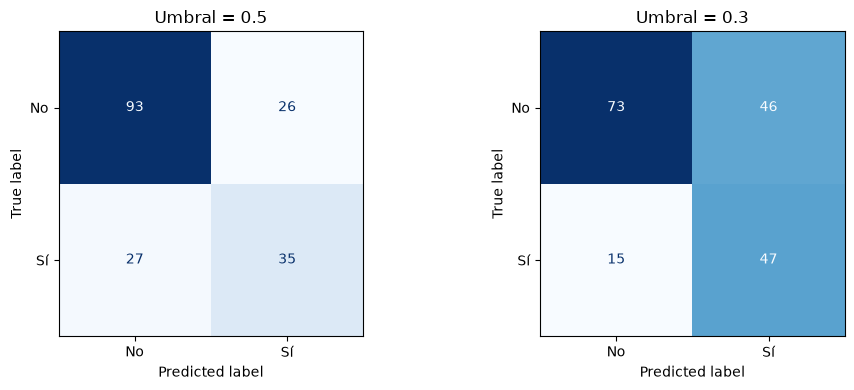

,exactitud,precision,sensibilidad,f1
Logística (umbral 0.5),0.707,0.574,0.565,0.569
Logística (umbral 0.3),0.663,0.505,0.758,0.606


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
filas = {}
for ax, u in zip(axes, [0.5, umbral_elegido]):
    pred_u = (p_hat_te >= u).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_te_c, pred_u, ax=ax, colorbar=False, cmap="Blues", display_labels=["No", "Sí"])
    ax.set_title(f"Umbral = {u}")
    filas[f"Logística (umbral {u})"] = metricas_clasificacion(y_te_c, pred_u)
plt.tight_layout()
plt.show()
pd.DataFrame(filas).T

**Respuesta.**

- `(p_hat >= 0.5)` reproduce exactamente `predict`: el modelo calcula una probabilidad y la clase sale de compararla con el umbral.
- Con el umbral 0.5, la sensibilidad en validación cruzada es ≈ 0.60. El umbral **más alto** con sensibilidad ≥ 0.80 es **0.30**, que además es donde la F1 llega a su máximo (≈ 0.71). En prueba, pasar de 0.5 a 0.3 sube la sensibilidad de 0.56 a **0.76** (de 35 a 47 casos detectados) y la F1 de 0.57 a 0.61, a cambio de bajar la precisión de 0.57 a 0.51 y la exactitud de 0.71 a 0.66.
- El umbral es una decisión más del modelo, como un hiperparámetro. Si lo elegimos mirando la prueba, la métrica que reportamos queda optimista porque la prueba deja de ser independiente. Por eso lo elegimos con K-Folds dentro del entrenamiento. Además, la meta de 0.80 en validación quedó en 0.76 en prueba: los resultados en datos nuevos nunca son idénticos.
- Para **tamizaje** (barato, no invasivo) conviene un umbral bajo como 0.3: preferimos citar de más a dejar pacientes en riesgo sin atención. Para un **tratamiento costoso o con efectos adversos** conviene un umbral alto, que priorice la precisión. El modelo es el mismo; lo que cambia es el costo de cada tipo de error.

---

<a id="ejercicio-9"></a>
<h2 style="color: #007ACC;">Ejercicio 9. KNN, SVM y árbol de clasificación</h2>

**Objetivo:** ajustar los tres clasificadores no lineales, con atención a lo que controla cada hiperparámetro (cuadernos 06, 07, 08 y 10).

Define `cv_clf = KFold(n_splits=5, shuffle=True, random_state=SEED)` y usa `scoring="f1"` en todas las búsquedas (en el cuaderno 04 vimos que la F1 combina precisión y sensibilidad, útil cuando la exactitud engaña).

**9a. KNN**

1. Con `cross_val_score` compara la F1 de un KNN con `k=15` **sin escalar** vs. **con** `StandardScaler`. Explica la diferencia mirando las escalas de `glucosa` y `pedigri` (`X_tr_c.describe()`).
2. Igual que en el cuaderno 10, recorre $k$ en `range(1, 80, 2)` y grafica la F1 de validación cruzada contra $k$. Agrega la F1 en **entrenamiento** (ajustando y prediciendo sobre `X_tr_c`). Señala las zonas de sobreentrenamiento y subentrenamiento.
3. Con `GridSearchCV` busca `n_neighbors` en `range(1, 80, 2)` y `metric` en `["euclidean", "manhattan"]` (cuaderno 07).

**9b. SVM**

4. Busca con `make_pipeline(StandardScaler(), SVC())` en una lista de grillas: kernel `linear` con `C` en `[0.01, 0.1, 1, 10]`; kernel `rbf` con `C` en `[0.1, 1, 10, 100]` y `gamma` en `[0.001, 0.01, 0.1, 1]`; kernel `poly` con `degree` en `[2, 3]` y `C` en `[0.1, 1, 10]`.
5. Con el mejor modelo reporta cuántos **vectores de soporte** tiene (`n_support_`) y qué fracción del entrenamiento representan. ¿Qué dice eso sobre qué tan separables son las clases?
6. Con `cv_results_` arma un mapa de calor de la F1 de validación para el kernel `rbf` (`C` × `gamma`). ¿Qué ocurre con `gamma=1`?

**9c. Árbol**

7. Para `max_depth` en `1..15` grafica la F1 de entrenamiento y la de validación cruzada. ¿Desde qué profundidad sobreentrena?
8. Busca `criterion` en `["gini", "entropy"]` (cuaderno 08), `max_depth` en `[2, 3, 4, 5, 6, 8]` y `min_samples_leaf` en `[1, 5, 10, 20, 40]`. ¿Importa el criterio?

In [29]:
cv_clf = KFold(n_splits=5, shuffle=True, random_state=SEED)

# 9a. KNN: el escalado importa
for nombre, m in [("sin escalar", KNeighborsClassifier(15)),
                  ("escalado", make_pipeline(StandardScaler(), KNeighborsClassifier(15)))]:
    s = cross_val_score(m, X_tr_c, y_tr_c, cv=cv_clf, scoring="f1")
    print(f"KNN k=15 {nombre:12s}: F1 = {s.mean():.3f} ± {s.std():.3f}")
X_tr_c.describe().T[["mean", "std", "min", "max"]]

KNN k=15 sin escalar : F1 = 0.610 ± 0.074


KNN k=15 escalado    : F1 = 0.582 ± 0.062


,mean,std,min,max
embarazos,3.715,3.340,0.000,17.000
glucosa,121.262,30.376,44.000,199.000
presion,72.438,12.536,24.000,122.000
imc,32.357,6.892,18.200,67.100
pedigri,0.484,0.350,0.078,2.420
edad,33.026,11.721,21.000,81.000


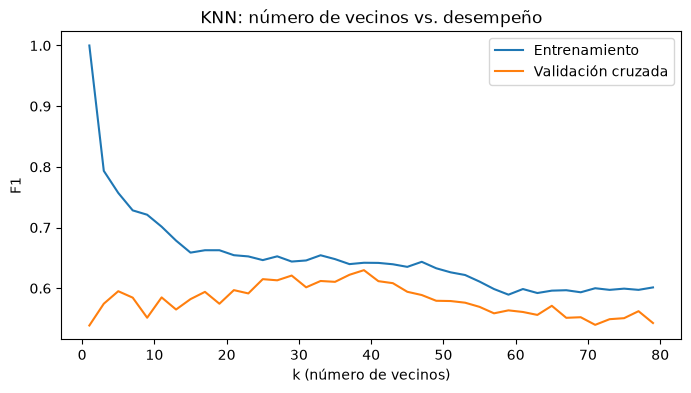

Mejores parámetros: {'kneighborsclassifier__metric': 'euclidean', 'kneighborsclassifier__n_neighbors': 39} | F1 CV: 0.63


In [30]:
k_values = list(range(1, 80, 2))
f1_cv, f1_train = [], []
for k in k_values:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    f1_cv.append(cross_val_score(knn, X_tr_c, y_tr_c, cv=cv_clf, scoring="f1").mean())
    f1_train.append(f1_score(y_tr_c, knn.fit(X_tr_c, y_tr_c).predict(X_tr_c)))

plt.figure(figsize=(8, 4))
plt.plot(k_values, f1_train, label="Entrenamiento")
plt.plot(k_values, f1_cv, label="Validación cruzada")
plt.xlabel("k (número de vecinos)")
plt.ylabel("F1")
plt.title("KNN: número de vecinos vs. desempeño")
plt.legend()
plt.show()

knn_clf = GridSearchCV(
    make_pipeline(StandardScaler(), KNeighborsClassifier()),
    {"kneighborsclassifier__n_neighbors": range(1, 80, 2),
     "kneighborsclassifier__metric": ["euclidean", "manhattan"]},
    cv=cv_clf, scoring="f1",
).fit(X_tr_c, y_tr_c)
print("Mejores parámetros:", knn_clf.best_params_, "| F1 CV:", round(knn_clf.best_score_, 3))

Mejores parámetros: {'svc__C': 10, 'svc__kernel': 'linear'} | F1 CV: 0.677
Vectores de soporte por clase: [130 128] -> 48% del entrenamiento


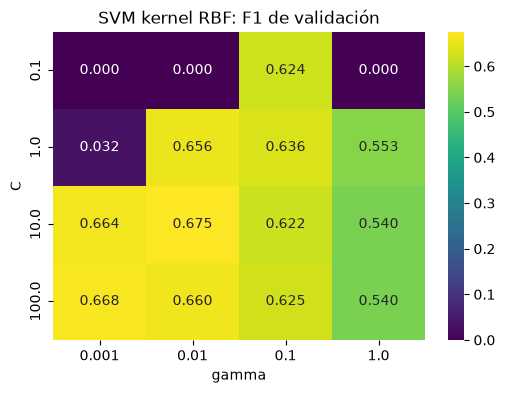

In [31]:
# 9b. SVM
svm_clf = GridSearchCV(
    make_pipeline(StandardScaler(), SVC()),
    [
        {"svc__kernel": ["linear"], "svc__C": [0.01, 0.1, 1, 10]},
        {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1]},
        {"svc__kernel": ["poly"], "svc__degree": [2, 3], "svc__C": [0.1, 1, 10]},
    ],
    cv=cv_clf, scoring="f1",
).fit(X_tr_c, y_tr_c)

svc = svm_clf.best_estimator_[-1]
print("Mejores parámetros:", svm_clf.best_params_, "| F1 CV:", round(svm_clf.best_score_, 3))
print(f"Vectores de soporte por clase: {svc.n_support_} -> {svc.n_support_.sum() / len(X_tr_c):.0%} del entrenamiento")

res = pd.DataFrame(svm_clf.cv_results_)
rbf = res[res["param_svc__kernel"] == "rbf"].pivot_table(
    index="param_svc__C", columns="param_svc__gamma", values="mean_test_score"
)
plt.figure(figsize=(6, 4))
sns.heatmap(rbf, annot=True, fmt=".3f", cmap="viridis")
plt.title("SVM kernel RBF: F1 de validación")
plt.xlabel("gamma")
plt.ylabel("C")
plt.show()

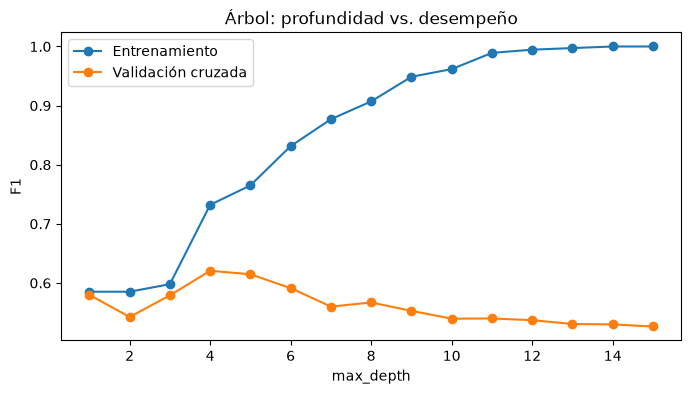

Mejores parámetros: {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 40} | F1 CV: 0.671


,mean,max
param_criterion,,
entropy,0.600,0.671
gini,0.601,0.657


In [32]:
# 9c. Árbol: profundidad vs. desempeño
profundidades = range(1, 16)
f1_cv, f1_train = [], []
for d in profundidades:
    arbol = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    f1_cv.append(cross_val_score(arbol, X_tr_c, y_tr_c, cv=cv_clf, scoring="f1").mean())
    f1_train.append(f1_score(y_tr_c, arbol.fit(X_tr_c, y_tr_c).predict(X_tr_c)))

plt.figure(figsize=(8, 4))
plt.plot(profundidades, f1_train, marker="o", label="Entrenamiento")
plt.plot(profundidades, f1_cv, marker="o", label="Validación cruzada")
plt.xlabel("max_depth")
plt.ylabel("F1")
plt.title("Árbol: profundidad vs. desempeño")
plt.legend()
plt.show()

arbol_clf = GridSearchCV(
    DecisionTreeClassifier(random_state=SEED),
    {"criterion": ["gini", "entropy"], "max_depth": [2, 3, 4, 5, 6, 8], "min_samples_leaf": [1, 5, 10, 20, 40]},
    cv=cv_clf, scoring="f1",
).fit(X_tr_c, y_tr_c)
print("Mejores parámetros:", arbol_clf.best_params_, "| F1 CV:", round(arbol_clf.best_score_, 3))

res = pd.DataFrame(arbol_clf.cv_results_)
res.groupby("param_criterion")["mean_test_score"].agg(["mean", "max"])

**Respuesta.**

- **KNN sin escalar vs. escalado:** sorpresa, aquí la F1 sin escalar (≈ 0.61) es algo **mayor** que con escalado (≈ 0.58), aunque la diferencia es menor que la desviación entre particiones (≈ 0.07). Sin escalar, `glucosa` (desviación ≈ 30) domina la distancia y `pedigri` (desviación ≈ 0.35) prácticamente no cuenta. Como la glucosa es justamente la variable más predictiva, ese peso "accidental" no perjudica. Escalar es la opción segura porque no sabemos de antemano qué variable importa; aquí la escala original coincidió por suerte con la importancia de las variables.
- **Curva de KNN:** con $k=1$ la F1 de entrenamiento es 1 y la de validación ≈ 0.54 (sobreentrenamiento). Al crecer $k$ las curvas se acercan, la validación llega a ≈ 0.62 alrededor de $k \approx 25$–$40$, y para $k$ muy grande ambas bajan (subentrenamiento). La búsqueda elige $k = 39$ con distancia euclidiana (F1 CV ≈ 0.63).
- **SVM:** gana el kernel **lineal** con `C=10` (F1 CV ≈ 0.68): en este problema no hace falta una frontera curva. El **48 %** del entrenamiento son vectores de soporte, así que las clases se solapan mucho (muchos puntos dentro del margen o mal clasificados). En el mapa del kernel RBF, con `C` y `gamma` pequeños la F1 es **0**: el modelo es tan suave que clasifica a todas como "no diabetes". Con `gamma=1` el kernel es muy local, el modelo memoriza y la F1 cae a ≈ 0.54.
- **Árbol:** la F1 de entrenamiento sube hasta 1 con la profundidad, mientras la de validación alcanza su máximo en profundidad 4 (≈ 0.62) y luego cae hasta ≈ 0.53: desde profundidad 5–6 **sobreentrena**. La búsqueda elige `entropy`, profundidad 4 y hojas de ≥ 40 observaciones (F1 CV ≈ 0.67). El criterio casi no importa: el promedio de F1 es 0.600 con entropía y 0.601 con Gini. Ambas medidas de impureza llevan a divisiones muy parecidas.

---

<a id="ejercicio-10"></a>
<h2 style="color: #007ACC;">Ejercicio 10. Comparación con validación cruzada</h2>

**Objetivo:** comparar los modelos de forma justa (mismas particiones, varias métricas, con su variabilidad) y solo al final mirar la prueba.

1. Reúne en un diccionario `modelos_clf` los mejores estimadores: Logística, KNN, SVM y Árbol.
2. Con `cross_val_score` y `cv_clf`, calcula para cada modelo la media y la desviación estándar de `"accuracy"`, `"precision"`, `"recall"` y `"f1"` sobre **entrenamiento**, y arma una tabla.
3. ¿Las diferencias de F1 entre modelos son mayores que la desviación estándar entre particiones?
4. Ahora sí, evalúa en **prueba**: dibuja las cuatro matrices de confusión lado a lado y agrega sus métricas a `resultados_clf`.
5. **Pregunta:** si tuvieras que elegir un modelo, ¿cuál y por qué? Considera desempeño, estabilidad e interpretabilidad (revisa las ventajas y desventajas de cada modelo en los cuadernos).

In [33]:
modelos_clf = {
    "Logística": logit,
    "KNN": knn_clf.best_estimator_,
    "SVM": svm_clf.best_estimator_,
    "Árbol": arbol_clf.best_estimator_,
}

tabla_cv = {}
for nombre, modelo in modelos_clf.items():
    tabla_cv[nombre] = {}
    for metrica in ["accuracy", "precision", "recall", "f1"]:
        s = cross_val_score(modelo, X_tr_c, y_tr_c, cv=cv_clf, scoring=metrica)
        tabla_cv[nombre][metrica] = f"{s.mean():.3f} ± {s.std():.3f}"
pd.DataFrame(tabla_cv).T

,accuracy,precision,recall,f1
Logística,0.792 ± 0.029,0.739 ± 0.058,0.601 ± 0.070,0.663 ± 0.065
KNN,0.786 ± 0.040,0.773 ± 0.087,0.532 ± 0.072,0.630 ± 0.077
SVM,0.795 ± 0.028,0.734 ± 0.057,0.629 ± 0.068,0.677 ± 0.061
Árbol,0.768 ± 0.024,0.661 ± 0.051,0.685 ± 0.020,0.671 ± 0.018


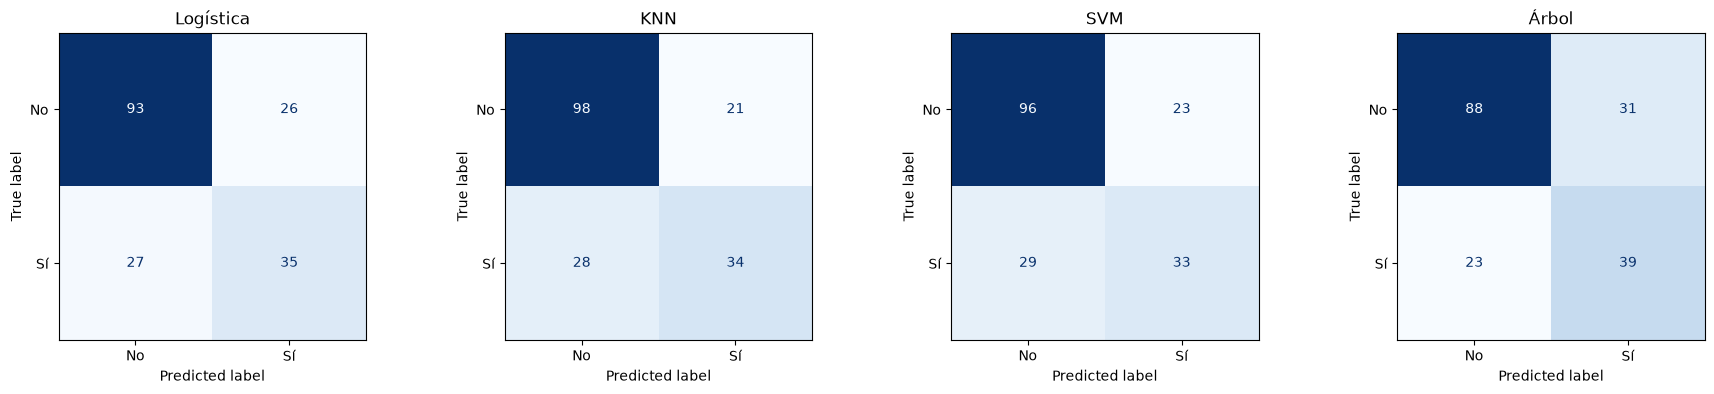

,exactitud,precision,sensibilidad,f1
Árbol,0.702,0.557,0.629,0.591
KNN,0.729,0.618,0.548,0.581
Logística,0.707,0.574,0.565,0.569
SVM,0.713,0.589,0.532,0.559
Referencia (siempre 0),0.657,0.000,0.000,0.000


In [34]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (nombre, modelo) in zip(axes, modelos_clf.items()):
    pred = modelo.predict(X_te_c)
    ConfusionMatrixDisplay.from_predictions(y_te_c, pred, ax=ax, colorbar=False, cmap="Blues", display_labels=["No", "Sí"])
    ax.set_title(nombre)
    resultados_clf[nombre] = metricas_clasificacion(y_te_c, pred)
plt.tight_layout()
plt.show()

pd.DataFrame(resultados_clf).T.sort_values("f1", ascending=False)

**Respuesta.**

- En validación cruzada, SVM (F1 ≈ 0.68), árbol (≈ 0.67) y logística (≈ 0.66) quedan muy cerca, y KNN algo atrás (≈ 0.63). La desviación entre particiones (≈ 0.02–0.08) es **del mismo orden** que esas diferencias: con 543 pacientes de entrenamiento no podemos afirmar que un modelo sea mejor que otro. El árbol es el más **estable** (desviación de F1 ≈ 0.02) y el de mayor sensibilidad.
- En prueba el orden cambia (árbol F1 ≈ 0.59, KNN ≈ 0.58, logística ≈ 0.57, SVM ≈ 0.56), algo esperable cuando las diferencias son pequeñas frente a la variabilidad. Todos superan con claridad a la referencia (sensibilidad 0). Ninguno detecta más de ≈ 63 % de los casos con el umbral por defecto.
- **Recomendación:** la **regresión logística**. Rinde igual que los modelos más complejos, entrega una probabilidad $\hat{p}$ que permite ajustar el umbral según el uso (Ejercicio 8) y sus coeficientes se explican fácilmente. El **árbol** es buena alternativa o complemento: es estable y produce reglas que un equipo clínico puede revisar.

---

<a id="ejercicio-11"></a>
<h2 style="color: #007ACC;">Ejercicio 11. Interpretación de clasificadores</h2>

**Objetivo:** explicar el modelo de forma **global** (qué variables importan y cómo es la frontera de decisión) y **local** (por qué esta paciente recibió esta predicción).

1. **Reglas del árbol.** Ajusta un `DecisionTreeClassifier(max_depth=3, min_samples_leaf=20)` y dibújalo con `plot_tree` (`class_names=["No", "Diabetes"]`, `proportion=True`). Redacta la regla que identifica el grupo de **mayor riesgo** y la de **menor riesgo**, con la proporción de diabetes de cada hoja. ¿Qué variable usa en la raíz? ¿Coincide con el coeficiente más grande de la logística?
2. **Fronteras de decisión.** Como en los cuadernos 06, 07 y 08, entrena los cuatro modelos usando solo `glucosa` e `imc` (con los mejores hiperparámetros encontrados) y dibuja sus fronteras con `DecisionBoundaryDisplay` sobre los datos de entrenamiento. Describe la forma de cada frontera.
3. **Una paciente.** Toma, de las pacientes **con diabetes** del conjunto de prueba, la que tenga la **menor $\hat{p}$** según la logística (el falso negativo "más seguro" del modelo).
   - Calcula **a mano** $t = \beta_0 + \sum_j \beta_j z_j$ (con $z_j$ la variable estandarizada) y $\hat{p} = \sigma(t) = 1/(1 + e^{-t})$. Verifica que coincide con `predict_proba`.
   - Grafica las contribuciones $\beta_j z_j$ de cada variable. ¿Qué la hace parecer de bajo riesgo?
   - ¿Qué predicen KNN y el árbol para ella? Recuerda que KNN asigna la clase de la mayoría de sus vecinos.
4. **Pregunta:** `edad` y `embarazos` están correlacionadas (revisa el mapa de calor). ¿Qué problema genera la **multicolinealidad** (cuaderno 03) al interpretar sus coeficientes?

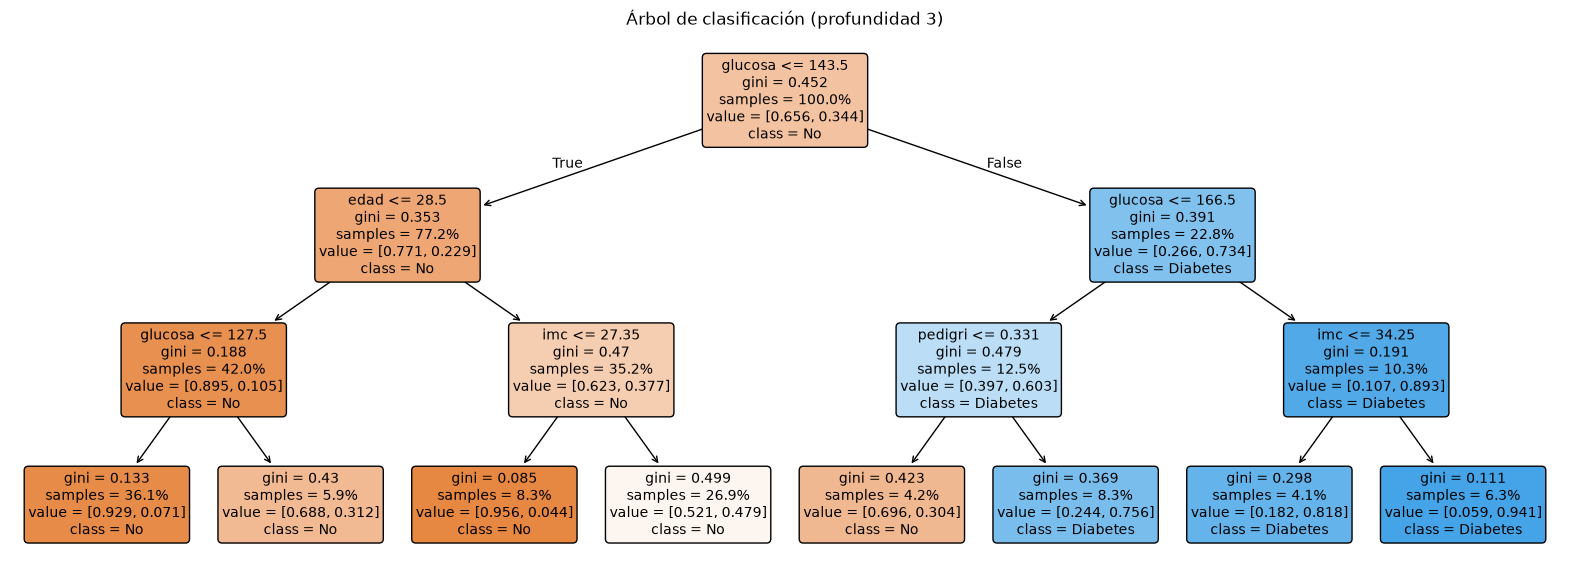

In [35]:
arbol_clf_3 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=SEED).fit(X_tr_c, y_tr_c)
plt.figure(figsize=(20, 7))
plot_tree(arbol_clf_3, feature_names=list(X_clf.columns), class_names=["No", "Diabetes"],
          filled=True, rounded=True, proportion=True, fontsize=10)
plt.title("Árbol de clasificación (profundidad 3)")
plt.show()

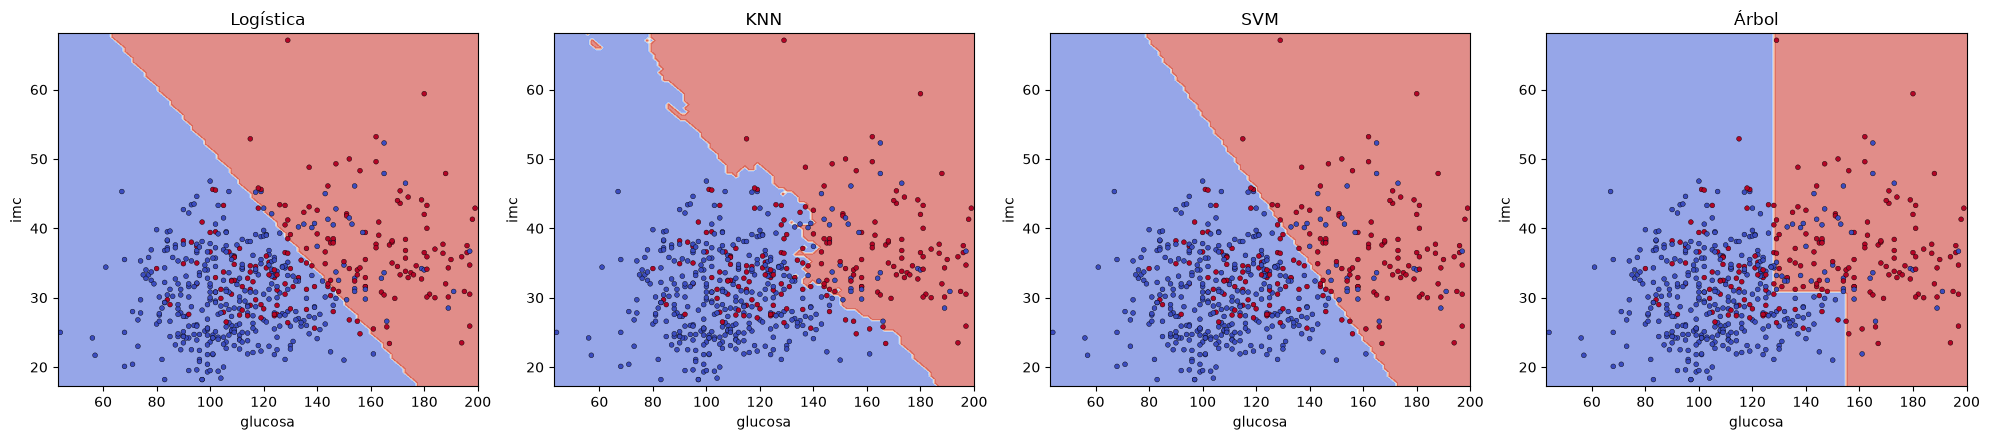

In [36]:
dos_vars = ["glucosa", "imc"]
X_tr_2 = X_tr_c[dos_vars]
p_knn, p_svm, p_arb = knn_clf.best_params_, svm_clf.best_params_, arbol_clf.best_params_
modelos_2d = {
    "Logística": make_pipeline(StandardScaler(), LogisticRegression()),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(
        n_neighbors=p_knn["kneighborsclassifier__n_neighbors"], metric=p_knn["kneighborsclassifier__metric"])),
    "SVM": make_pipeline(StandardScaler(), SVC(**{k.replace("svc__", ""): v for k, v in p_svm.items()})),
    "Árbol": DecisionTreeClassifier(random_state=SEED, **p_arb),
}

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (nombre, modelo) in zip(axes, modelos_2d.items()):
    modelo.fit(X_tr_2, y_tr_c)
    DecisionBoundaryDisplay.from_estimator(modelo, X_tr_2, response_method="predict", cmap=plt.cm.coolwarm,
                                           alpha=0.6, ax=ax, xlabel="glucosa", ylabel="imc")
    ax.scatter(X_tr_2["glucosa"], X_tr_2["imc"], c=y_tr_c, cmap=plt.cm.coolwarm, s=12, edgecolors="k", linewidths=0.3)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

Paciente 6 (diabetes = 1)


,embarazos,glucosa,presion,imc,pedigri,edad
6,3,78,50,31.000,0.248,26


t = -0.917 + -2.293 = -3.209
p = 1/(1+e^-t) = 0.039 | predict_proba = 0.039


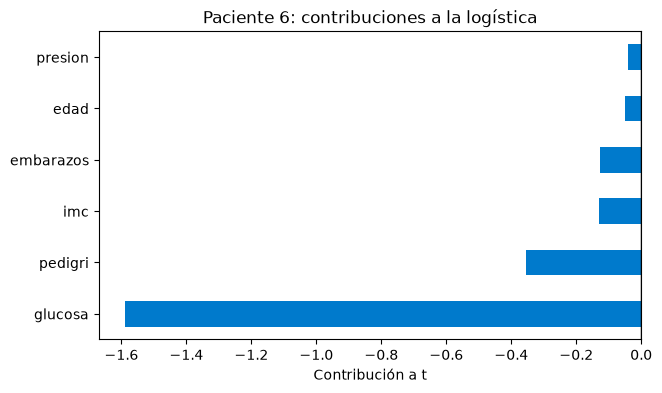

KNN    predice: 0
SVM    predice: 0
Árbol  predice: 0
Proporción de vecinos con diabetes (KNN): 0.026


In [37]:
positivas = X_te_c[y_te_c == 1]
idx = pd.Series(logit.predict_proba(positivas)[:, 1], index=positivas.index).idxmin()
paciente = X_te_c.loc[[idx]]
print("Paciente", idx, "(diabetes = 1)")
display(paciente)

z = logit[0].transform(paciente)[0]
contrib = pd.Series(logit[-1].coef_[0] * z, index=X_clf.columns)
t = logit[-1].intercept_[0] + contrib.sum()
print(f"t = {logit[-1].intercept_[0]:.3f} + {contrib.sum():.3f} = {t:.3f}")
print(f"p = 1/(1+e^-t) = {1 / (1 + np.exp(-t)):.3f} | predict_proba = {logit.predict_proba(paciente)[0, 1]:.3f}")

contrib = contrib.sort_values()
ax = contrib.plot.barh(figsize=(7, 4), color=np.where(contrib > 0, "#d62728", "#007ACC"))
ax.axvline(0, c="k", lw=1)
ax.set(xlabel="Contribución a t", title=f"Paciente {idx}: contribuciones a la logística")
plt.show()

for nombre in ["KNN", "SVM", "Árbol"]:
    print(f"{nombre:6s} predice: {modelos_clf[nombre].predict(paciente)[0]}")
print("Proporción de vecinos con diabetes (KNN):", round(modelos_clf["KNN"].predict_proba(paciente)[0, 1], 3))

**Respuesta.**

- **Reglas del árbol:** la raíz divide por `glucosa ≤ 143.5`, la misma variable con el coeficiente más grande en la logística. El grupo de **mayor riesgo** es *glucosa > 166.5 e IMC > 34.25* (32 de 34 ≈ 94 % con diabetes), seguido de *glucosa > 166.5 e IMC ≤ 34.25* (82 %) y *glucosa entre 143.5 y 166.5 con pedigrí > 0.33* (76 %). El de **menor riesgo** es *glucosa ≤ 143.5, más de 28.5 años e IMC ≤ 27.35* (2 de 45 ≈ 4 %), y luego *glucosa ≤ 127.5 y hasta 28.5 años* (7 %, el grupo más numeroso).
- **Fronteras de decisión** (glucosa vs. IMC): la logística y el SVM lineal trazan una **recta** casi idéntica, que sube el riesgo con más glucosa y más IMC. KNN dibuja una frontera parecida pero **irregular**, que sigue a los puntos de su vecindad. El árbol divide el plano en **rectángulos** (cortes paralelos a los ejes en glucosa ≈ 128 y ≈ 155 e IMC ≈ 31). En los cuatro hay una gran zona de solapamiento entre glucosa 100–140, donde ningún modelo puede separar bien las clases.
- **Paciente mal clasificada** (índice 6): 26 años, glucosa **78 mg/dL** (muy por debajo de la media de 121), IMC 31 y pedigrí bajo. El cálculo a mano da $t = -0.917 - 2.293 = -3.209$ y $\hat{p} = \sigma(t) \approx 0.039$, igual que `predict_proba`. La contribución de la glucosa (≈ −1.6) domina; el resto aporta poco y también es negativo. KNN, SVM y árbol también la clasifican como "no diabetes" (solo 1 de sus 39 vecinos tiene diabetes). El modelo no está "roto": con estas variables **es indistinguible** de las pacientes sanas. Mejorar este caso requiere más información (por ejemplo, mediciones repetidas en el tiempo), no un modelo más complejo.
- **Multicolinealidad:** `edad` y `embarazos` tienen correlación ≈ 0.56. Cuando dos variables comparten información, el modelo puede repartir el efecto entre ellas de forma arbitraria. Aquí la logística le da casi todo el peso a `embarazos` (0.60) y casi nada a `edad` (0.08), aunque `edad` está **más** correlacionada con la diabetes (0.25) que `embarazos` (0.22). Si quitamos una, la otra absorbe su efecto. Por eso un coeficiente pequeño **no** prueba que la variable no importe, y en todo caso son asociaciones, no efectos causales.

---

<a id="ejercicio-integrador"></a>
<h2 style="color: #007ACC;">Ejercicio integrador. Informe para el comité</h2>

Escribe, **en no más de una página** (Markdown en este cuaderno), dos informes breves dirigidos a personas no técnicas:

**A. Aseguradora (Parte I)**

- Modelo recomendado para tarificar y su error esperado (en USD, con la métrica adecuada).
- Los tres factores que más mueven el costo y la magnitud de su efecto, incluido el efecto conjunto de fumar y la obesidad.
- Un riesgo ético o regulatorio de usar `sex` o `region` en la prima, y si el modelo realmente las necesita (usa tu evidencia).

**B. Programa de prevención de diabetes (Parte II)**

- Modelo y **umbral** recomendados, con la matriz de confusión esperada por cada 100 pacientes evaluadas.
- Qué significan en la práctica la sensibilidad y la precisión elegidas (cuántas pacientes en riesgo se escapan y cuántas citas "innecesarias" se generan).
- Dos limitaciones del análisis (por ejemplo: población específica, tamaño de muestra, variables eliminadas, asociación vs. causalidad) y qué datos adicionales pedirías.

In [38]:
# Insumos numéricos para el informe
print("Regresión — prueba:")
display(pd.DataFrame(resultados_reg).T.sort_values("MAE"))

pred_u = (p_hat_te >= umbral_elegido).astype(int)
cm = pd.crosstab(pd.Series(y_te_c.values, name="Real"), pd.Series(pred_u, name="Predicho"), normalize="all") * 100
print(f"Clasificación — logística con umbral {umbral_elegido}, matriz por cada 100 pacientes:")
cm.round(1)

Regresión — prueba:


,MAE,RMSE,R2
SVR,"1,846.547","4,737.592",0.855
Lineal + transformaciones,"2,390.440","4,364.346",0.877
Lasso,"2,390.457","4,364.360",0.877
Ridge,"2,390.470","4,364.366",0.877
Árbol,"2,666.824","4,509.200",0.869
KNN,"3,405.163","5,609.183",0.797
Lineal,"4,181.194","5,796.285",0.784
Referencia (media),"9,593.338","12,465.610",-0.001


Clasificación — logística con umbral 0.3, matriz por cada 100 pacientes:


Predicho,0,1
Real,,
0,40.300,25.400
1,8.300,26.000


**Ejemplo de informe (los números exactos dependen de la ejecución).**

**A. Aseguradora.** Recomendamos la **regresión lineal con las variables transformadas** (edad al cuadrado y la indicadora de fumador obeso). Se equivoca en promedio en ≈ 2 400 USD por asegurado, frente a ≈ 9 600 USD si se cobrara a todos el costo promedio. Tiene el mejor $R^2$ (0.88) y es una fórmula que se puede auditar y explicar a un regulador. El SVR reduce el error medio a ≈ 1 850 USD, pero es difícil de explicar y se comporta de forma extraña con IMC muy altos; solo se justifica si esa diferencia pesa más que la transparencia. El costo lo explican casi por completo tres factores: **fumar** (≈ +23 650 USD/año en promedio), la **edad** (cada vez más rápido en edades altas) y el **IMC**, cuyo efecto aparece casi solo en fumadores: un fumador obeso cuesta ≈ 20 000 USD más que uno con IMC normal. `sex` y `region` casi no aportan (no son significativas en el modelo base, Lasso las elimina primero y el árbol no las usa). Usarlas en la prima expondría a la compañía a acusaciones de discriminación sin ganancia real en precisión, así que recomendamos excluirlas.

**B. Prevención de diabetes.** Recomendamos la **regresión logística** con un **umbral de 0.3** (elegido con validación cruzada para detectar al menos 80 % de los casos). Por cada 100 mujeres evaluadas, el modelo identifica a ≈ 26 de las ≈ 34 que desarrollarán diabetes (sensibilidad ≈ 0.76) y cita a ≈ 25 que no la desarrollarán (precisión ≈ 0.51). Se escapan ≈ 8 casos, casi siempre con glucosa normal en la medición. La variable clave es la **glucosa**, seguida del IMC, el número de embarazos y los antecedentes familiares. *Limitaciones:* (1) los datos provienen de una sola población (mujeres pima de 21 años o más) y no se deben aplicar a otras poblaciones sin validarlos; (2) la muestra es pequeña (724 pacientes tras la limpieza) y tuvimos que descartar insulina y pliegue cutáneo por exceso de ceros imposibles. Sugerimos medir esas variables correctamente, agregar mediciones repetidas en el tiempo y recordar que las asociaciones encontradas no son causales.